# Qui a écrit ce code : vous, l'IA… ou les deux ?
## *Ce que vos commits disent de vous — et de l'IA qui vous assiste.*

---

**Message central de ce talk :**

> *Le style est une empreinte mesurable.*
> *Mais mesurer une différence ne dit pas ce qui l'a causée.*

---

## 3 démos — 40 minutes de contenu

| Acte | Question | Démo | Timing |
|------|----------|------|--------|
| **Acte 1** | Est-ce que ça marche ? | Live 1 — les 4 tests de Juola, sur du code | 7:30–15:00 |
| **Acte 2** | Que mesure-t-on vraiment ? | Live 2 — l'auteur, ou le sujet ? | 15:00–17:30 |
| **Acte 3** | Que change l'IA ? | Live 3 — votre code, puis celui de la machine | 22:15–26:30 |

---

## Zéro dépendance maison

Ce notebook n'importe que `numpy`, `matplotlib`, `re`, `collections` et `os`.
Aucun import maison, aucun appel réseau, aucun GPU : chaque mesure tient en
quelques lignes que la salle peut relire pendant que je parle.

Tout — notebook, corpus, scripts de mesure — est dans un seul dépôt :
[`devoxx2027-stylometrie`](https://github.com/riadmaouchi/devoxx2027-stylometrie)

Les mesures qui ne tiennent pas dans un live sont dans quatre dépôts à part :
[`dev-fingerprint`](https://github.com/riadmaouchi/dev-fingerprint) (6 670 commits, 11 développeurs) ·
[`copilot-signal`](https://github.com/riadmaouchi/copilot-signal) (147 paires appariées) ·
[`llm-style-fingerprints`](https://github.com/riadmaouchi/llm-style-fingerprints) (80 extraits, 4 modèles) ·
[`stylometry-python`](https://github.com/riadmaouchi/stylometry-python) (la librairie)

---

## Installation
```bash
pip install numpy matplotlib
```
**Kernel → Restart & Run All** pour tester avant le talk.

---

## Imports — exécuter en premier


In [1]:
# ── CONTROLE DE DEPART ──────────────────────────────────────────────
# Ce notebook ne vit pas seul : il lit corpus/ et experiments/, qui sont
# dans le meme dossier que lui. Ouvert ailleurs, il le dit ici, tout de
# suite, au lieu de planter trente cellules plus bas.
import os, sys
try:
    import numpy as np
    import matplotlib.pyplot as plt
except ImportError as e:
    raise ImportError(f"Il manque {e.name}.  ->  pip install -r requirements.txt") from None
from collections import Counter
import re

def _trouver_le_depot():
    d = os.getcwd()
    for _ in range(4):                       # ici, puis jusqu'a 3 dossiers au-dessus
        for cand in (d, os.path.join(d, 'devoxx2027-stylometrie')):
            if os.path.isfile(os.path.join(cand, 'corpus', 'devs', 'dev_1.py')):
                return cand
        d = os.path.dirname(d)
    return None

_depot = _trouver_le_depot()
if _depot is None:
    raise FileNotFoundError(
        "\n\n  LE DOSSIER corpus/ EST INTROUVABLE.\n"
        f"  Le notebook tourne depuis : {os.getcwd()}\n\n"
        "  Ce fichier .ipynb ne suffit pas : il lui faut corpus/ et experiments/.\n"
        "  1. Decompresse devoxx2027-stylometrie.zip\n"
        "  2. Ouvre le notebook qui est DANS le dossier devoxx2027-stylometrie/\n"
        "  3. Kernel -> Restart & Run All\n")
os.chdir(_depot)
_manque = [p for p in ('corpus/devs/dev_1.py', 'corpus/zola_germinal.txt', 'corpus/neuf/humain_1.py',
                       'corpus/ia/assistant.py', 'corpus/eras/avant.py',
                       'experiments/fuite_blocs.py', 'experiments/piege_projet.py')
           if not os.path.isfile(p)]
if _manque:
    raise FileNotFoundError("Depot incomplet, il manque : " + ', '.join(_manque))

# ── PALETTE DE SCENE ────────────────────────────────────────────────
# Validee pour fond sombre et daltonisme (protan/deutan/tritan).
ACCENT, BLEU, VIOLET = '#E4611F', '#0C8EC7', '#8B5CF6'
FOND, PANNEAU        = '#0D1117', '#161B22'
ENCRE, ENCRE2, GRIS  = '#E6EDF3', '#9CA3AF', '#30363D'

def scene(w=14, h=6):
    """Une figure prete a projeter : fond sombre, axes recessifs, gros texte."""
    fig, ax = plt.subplots(figsize=(w, h))
    fig.patch.set_facecolor(FOND); ax.set_facecolor(FOND)
    for s in ax.spines.values(): s.set_visible(False)
    ax.tick_params(colors=ENCRE2, labelsize=14, length=0)
    ax.grid(axis='x', color=GRIS, lw=0.8, alpha=.6); ax.set_axisbelow(True)
    return fig, ax

print(f'OK — depot : {os.path.basename(_depot)}/')
print(f'     Python {sys.version.split()[0]} · numpy {np.__version__} · '
      f'matplotlib {plt.matplotlib.__version__} · corpus et experiments presents')

OK — depot : devoxx2027-stylometrie/
     Python 3.13.18 · numpy 2.5.3 · matplotlib 3.11.2 · corpus et experiments presents


---

## 🔴 OUVERTURE — Deux fonctions, deux personnes

**🎙️** *"Avant toute théorie. Deux fonctions. Le même travail.*
*Même personne, ou deux personnes différentes ?"*

*(Écrits pour la démo, dans deux styles, par la même personne — le dire après le vote. 20 secondes de lecture, puis vote.)*


In [2]:
# ── DEUX FONCTIONS. MÊME RÉSULTAT. PAS LE MÊME AUTEUR. ───────────────
import re
import numpy as np
from collections import Counter

EXTRAIT_1 = """
# Tri des elements d une liste
def sortElements(inputList, reverseOrder):
    if inputList == None or len(inputList) == 0:
        return []
    resultList = []
    for i in range(len(inputList)):
        resultList.append(inputList[i])
    for i in range(len(resultList)):
        for j in range(i + 1, len(resultList)):
            if resultList[i] > resultList[j]:
                tempValue = resultList[i]
                resultList[i] = resultList[j]
                resultList[j] = tempValue
    return resultList
"""

EXTRAIT_2 = """
def sort_elements(lst, reverse=False):
    if not lst:
        return []
    return sorted(lst, reverse=reverse)
"""

for titre, src in [('EXTRAIT 1', EXTRAIT_1), ('EXTRAIT 2', EXTRAIT_2)]:
    print('╔' + '═'*56 + '╗')
    print(f'║  {titre:<54}║')
    print('╚' + '═'*56 + '╝')
    for l in src.strip().split('\n'):
        print('  ' + l)
    print()
print('─'*58)
print('  Deux personnes ? Ou la même, deux jours différents ?')
print('─'*58)

╔════════════════════════════════════════════════════════╗
║  EXTRAIT 1                                             ║
╚════════════════════════════════════════════════════════╝
  # Tri des elements d une liste
  def sortElements(inputList, reverseOrder):
      if inputList == None or len(inputList) == 0:
          return []
      resultList = []
      for i in range(len(inputList)):
          resultList.append(inputList[i])
      for i in range(len(resultList)):
          for j in range(i + 1, len(resultList)):
              if resultList[i] > resultList[j]:
                  tempValue = resultList[i]
                  resultList[i] = resultList[j]
                  resultList[j] = tempValue
      return resultList

╔════════════════════════════════════════════════════════╗
║  EXTRAIT 2                                             ║
╚════════════════════════════════════════════════════════╝
  def sort_elements(lst, reverse=False):
      if not lst:
          return []
      return sorte

⏸️ **La salle a voté :**


In [3]:
# ── CE QUE VOUS VENEZ DE FAIRE À L'ŒIL, EN CHIFFRES ──────────────────
def signature_courte(src):
    lignes = [l for l in src.split('\n') if l.strip()]
    n = max(len(lignes), 1)
    noms = re.findall(r'\b([a-zA-Z_][a-zA-Z0-9_]+)\b', src); nn = max(len(noms), 1)
    return {
        'camelCase'      : len(re.findall(r'[a-z][A-Z]', src))/nn,
        'snake_case'     : len([x for x in noms if '_' in x and x == x.lower() and len(x) > 2])/nn,
        'commentaires'   : sum(1 for l in lignes if l.strip().startswith('#'))/n,
        '== None'        : len(re.findall(r'==\s*None', src))/n,
        'range(len(...))': len(re.findall(r'range\s*\(\s*len\s*\(', src))/n,
        'lignes'         : n,
    }

s1, s2 = signature_courte(EXTRAIT_1), signature_courte(EXTRAIT_2)
print(f"{'':20}{'extrait 1':>12}{'extrait 2':>12}")
print('-'*44)
for k in s1:
    v1, v2 = s1[k], s2[k]
    fmt = (lambda v: f'{v:>12.0f}') if k == 'lignes' else (lambda v: f'{v:>12.2f}')
    flag = '   <--' if abs(v1-v2) > (2 if k == 'lignes' else 0.05) else ''
    print(f'  {k:<18}{fmt(v1)}{fmt(v2)}{flag}')
print('-'*44)
print()
print('Six nombres. Aucun ne parle de ce que fait la fonction.')
print('Tous parlent de qui l a ecrite.')
print()
print('Vous venez de faire de la stylometrie. Sans le savoir,')
print('et exactement comme on l a fait sur une romanciere en 2013.')

                       extrait 1   extrait 2
--------------------------------------------
  camelCase                 0.43        0.00   <--
  snake_case                0.00        0.07   <--
  commentaires              0.07        0.00   <--
  == None                   0.07        0.00   <--
  range(len(...))           0.14        0.00   <--
  lignes                      14           4   <--
--------------------------------------------

Six nombres. Aucun ne parle de ce que fait la fonction.
Tous parlent de qui l a ecrite.

Vous venez de faire de la stylometrie. Sans le savoir,
et exactement comme on l a fait sur une romanciere en 2013.


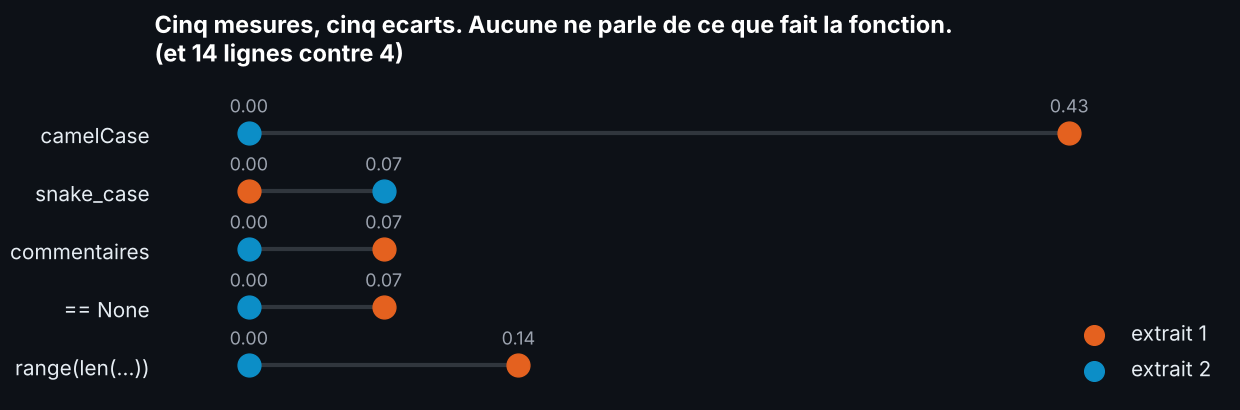

In [4]:
# ── LES SIX NOMBRES, EN UNE IMAGE ───────────────────────────────────
# Les cinq ratios partagent une echelle ; « lignes » est d'une autre
# nature et reste en sous-titre plutot que de fausser l'axe.
_cles = [k for k in s1 if k != 'lignes'][::-1]
fig, ax = scene(12.5, 4.2)
for i, k in enumerate(_cles):
    v1, v2 = s1[k], s2[k]
    ax.plot([v1, v2], [i, i], color=GRIS, lw=3, zorder=2)
    ax.scatter([v1], [i], s=270, color=ACCENT, zorder=4)
    ax.scatter([v2], [i], s=270, color=BLEU, zorder=4)
    for v, c in ((v1, ACCENT), (v2, BLEU)):
        ax.text(v, i + .28, f'{v:.2f}', color=ENCRE2, fontsize=13,
                ha='center', va='bottom')
ax.set_yticks(range(len(_cles))); ax.set_yticklabels(_cles, color=ENCRE, fontsize=15)
ax.set_xticks([]); ax.set_xlim(-.05, .52); ax.set_ylim(-.6, len(_cles) - .15)
ax.scatter([], [], s=200, color=ACCENT, label='extrait 1')
ax.scatter([], [], s=200, color=BLEU, label='extrait 2')
leg = ax.legend(loc='lower right', fontsize=15, frameon=False)
for t in leg.get_texts(): t.set_color(ENCRE)
ax.set_title("Cinq mesures, cinq ecarts. Aucune ne parle de ce que fait la fonction.\n"
             f"(et {s1['lignes']:.0f} lignes contre {s2['lignes']:.0f})",
             color='white', fontsize=17, fontweight='bold', pad=16, loc='left')
ax.title.set_linespacing(1.6)
plt.tight_layout(); plt.show()

---
---
# ACTE 1 — Votre code a-t-il une signature ?

**Timing : 2:00 → 15:00**

## Le message

> *"Vous ne choisissez pas la moitié de ce que vous écrivez."*

En 2013, quatre mesures pointent vers J.K. Rowling — sans le prouver.
On va refaire ses quatre tests — mais sur du code.


In [5]:
# ── CORPUS — 3 développeurs réels, un seul dépôt ─────────────────────
# corpus/devs/ : lignes reellement ajoutees par 3 contributeurs de
# github.com/django/django (BSD-3-Clause), anonymises.
#
# Corpus CONTROLE : meme depot, meme epoque (2015-2021, un seul regime de
# mise en forme), meme type de code (bibliotheque, pas de tests), commits de
# 300 lignes au plus. La regle entiere : experiments/construire_corpus.py.
# POURQUOI tant de precautions : Acte 2, piege 2.
from collections import Counter

DEVS = {f'Dev {i}': f'corpus/devs/dev_{i}.py' for i in (1, 2, 3)}

def charger_code(chemin):
    # On ne retire QUE les en-tetes que j'ai ajoutes moi-meme. Surtout pas les
    # commentaires des developpeurs : la densite de commentaires est l'une des
    # features que ce talk mesure. Les supprimer, c'est mesurer mon chargeur.
    return [l for l in open(chemin, encoding='utf-8').read().split('\n')
            if l.strip() and not l.startswith('# Lignes ajoutees')
            and not l.startswith('# Extraites')]

CODE = {d: charger_code(p) for d, p in DEVS.items()}
for d in DEVS:
    print(f'  {d} : {len(CODE[d]):>6,} lignes'.replace(',', ' '))

def blocs_code(L, n):
    return ['\n'.join(L[i:i+n]) for i in range(0, len(L)-n+1, n)]

REF = {d: '\n'.join(CODE[d][:1200]) for d in DEVS}   # references
print('\nReferences : 1 200 lignes par developpeur.')
print('Corpus controle : meme depot, meme epoque, meme type de code.')
print('Le pourquoi, et les degats : Acte 2.')

  Dev 1 :  3 000 lignes
  Dev 2 :  3 000 lignes
  Dev 3 :  3 000 lignes

References : 1 200 lignes par developpeur.
Corpus controle : meme depot, meme epoque, meme type de code.
Le pourquoi, et les degats : Acte 2.


---

### Du code au vecteur — les trois gestes, en vrai

**🎙️** *"Les mêmes trois gestes, mais sur du code. Quarante-et-un tokens au lieu de*
*quarante-et-un mots, un vecteur par passage, et l'angle entre deux passages."*

*(1 Shift+Enter. C'est la seule fois où l'on voit la mécanique nue : après, elle est dans les fonctions.)*


GESTE 1   41 tokens :  .  (  )  '  ,  =  :  self  "  %  if  return  #  s  [  ]  0  in  -  from  *  the  ...
GESTE 2   un passage de Dev 1, 2000 tokens  ->  41 nombres, longueur 1.00
          [0.52  0.41  0.42  0.35  0.26  0.20  0.19  0.13  0.07  ...]


GESTE 3   distance mediane entre deux passages, sur 533 paires :
             meme developpeur        0.051
             deux developpeurs       0.071


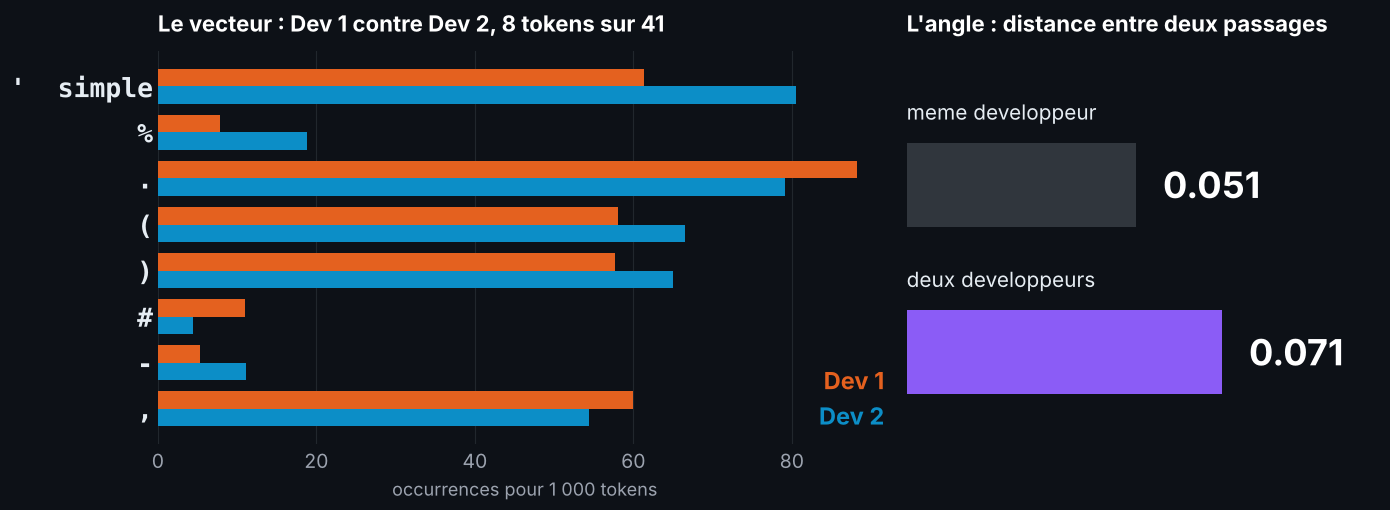

Pas de modele, pas d entrainement : du comptage et de la trigonometrie.
Un ecart de x1.4. Il est la, et il est mince : une seule paire de
passages ne suffit pas. Il faut du volume, et plusieurs mesures. C est la suite.


In [6]:
# ── DU CODE AU VECTEUR — LES TROIS GESTES ───────────────────────────
tokens = lambda src: re.findall(r'[A-Za-z_]+|[^\sA-Za-z_]', src)   # un mot, ou un signe
_T = {d: tokens('\n'.join(CODE[d])) for d in DEVS}

# GESTE 1 — ON FIXE UNE LISTE.  Les 41 tokens les plus frequents du corpus :
#           ce qu'on tape sans y penser.
MOTS = [t for t, _ in Counter(t for d in DEVS for t in _T[d]).most_common(41)]

# GESTE 2 — ON COMPTE, ET ON NORMALISE.  Un passage devient une direction.
def vecteur(toks):
    c = Counter(toks); n = max(len(toks), 1)
    v = np.array([c[m] / n for m in MOTS]); k = np.linalg.norm(v)
    return v / k if k > 0 else v             # longueur 1 : 50 lignes ou 500, meme echelle

# GESTE 3 — ON COMPARE DEUX DIRECTIONS.  0 = meme direction.
def dist(a, b):
    return 1 - float(np.dot(a, b))           # 1 - cosinus de l'angle

_N = 2000                                    # un passage = 2 000 tokens, ~220 lignes
_v = vecteur(_T['Dev 1'][:_N])
print(f'GESTE 1   {len(MOTS)} tokens :  ' + '  '.join(MOTS[:22]) + '  ...')
print(f'GESTE 2   un passage de Dev 1, {_N} tokens  ->  {len(_v)} nombres, longueur {np.linalg.norm(_v):.2f}')
print('          [' + '  '.join(f'{x:.2f}' for x in _v[:9]) + '  ...]')

# Une seule paire de passages ne dit rien : on en tire quelques centaines.
_rng = np.random.default_rng(1); _meme, _autre = [], []; _noms = list(DEVS)
for _ in range(600):
    d = _noms[_rng.integers(3)]; e = _noms[(_noms.index(d) + 1 + _rng.integers(2)) % 3]
    a, b = _rng.integers(0, len(_T[d]) - _N, 2); c = _rng.integers(0, len(_T[e]) - _N)
    if abs(a - b) < _N: continue             # deux passages qui se chevauchent : ecartes
    _meme.append(dist(vecteur(_T[d][a:a + _N]), vecteur(_T[d][b:b + _N])))
    _autre.append(dist(vecteur(_T[d][a:a + _N]), vecteur(_T[e][c:c + _N])))
_dm, _da = float(np.median(_meme)), float(np.median(_autre))
print(f'GESTE 3   distance mediane entre deux passages, sur {len(_meme)} paires :')
print(f'             meme developpeur        {_dm:.3f}')
print(f'             deux developpeurs       {_da:.3f}')

# ── L'IMAGE : le profil a gauche, l'angle a droite ──────────────────
_p = {d: {m: 1000 * Counter(_T[d])[m] / len(_T[d]) for m in MOTS} for d in ('Dev 1', 'Dev 2')}
_top = sorted(MOTS, key=lambda m: -abs(_p['Dev 1'][m] - _p['Dev 2'][m]))[:8][::-1]
fig, (ax, bx) = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={'width_ratios': [1.55, 1]})
fig.patch.set_facecolor(FOND)
for a_ in (ax, bx):
    a_.set_facecolor(FOND)
    for sp in a_.spines.values(): sp.set_visible(False)
    a_.tick_params(colors=ENCRE2, labelsize=14, length=0)
y = np.arange(len(_top)); h = .38
ax.barh(y + h / 2, [_p['Dev 1'][m] for m in _top], height=h, color=ACCENT, zorder=3)
ax.barh(y - h / 2, [_p['Dev 2'][m] for m in _top], height=h, color=BLEU, zorder=3)
_nom = {'"': '"  double', "'": "'  simple", '`': '`  backtick'}    # lisible du fond de la salle
ax.set_yticks(y); ax.set_yticklabels([_nom.get(m, m) for m in _top], color=ENCRE, fontsize=19,
                                     fontweight='bold', family='monospace')
ax.grid(axis='x', color=GRIS, lw=.8, alpha=.6); ax.set_axisbelow(True)
ax.set_xlabel('occurrences pour 1 000 tokens', color=ENCRE2, fontsize=13)
ax.text(.99, .14, 'Dev 1', color=ACCENT, fontsize=17, fontweight='bold', ha='right', transform=ax.transAxes)
ax.text(.99, .05, 'Dev 2', color=BLEU, fontsize=17, fontweight='bold', ha='right', transform=ax.transAxes)
ax.set_title('Le vecteur : Dev 1 contre Dev 2, 8 tokens sur 41',
             color='white', fontsize=16, fontweight='bold', pad=14, loc='left')
bx.barh([1, 0], [_dm, _da], height=.5, color=[GRIS, VIOLET], zorder=3)
for yy, vv, nn in ((1, _dm, 'meme developpeur'), (0, _da, 'deux developpeurs')):
    bx.text(vv + .006, yy, f'{vv:.3f}', color='white', fontsize=26, fontweight='bold', va='center')
    bx.text(0, yy + .36, nn, color=ENCRE, fontsize=15, va='bottom')
bx.set_xlim(0, _da * 1.5); bx.set_ylim(-.55, 1.8); bx.set_xticks([]); bx.set_yticks([])
bx.set_title("L'angle : distance entre deux passages", color='white', fontsize=16,
             fontweight='bold', pad=14, loc='left')
plt.tight_layout(); plt.show()
print('Pas de modele, pas d entrainement : du comptage et de la trigonometrie.')
print(f'Un ecart de x{_da / _dm:.1f}. Il est la, et il est mince : une seule paire de')
print('passages ne suffit pas. Il faut du volume, et plusieurs mesures. C est la suite.')


In [7]:
# ── LES 4 FAMILLES DE MESURES DE 2013, TRANSPOSEES AU CODE ──────────
# Ce n'est pas l'experience de Juola rejouee a l'identique : c'est la MEME
# FAMILLE de mesures, transposee. Lui comptait des mots, je compte des tokens.
# 2013 : longueur des mots · 100 mots frequents · paires de mots · 4-grammes
# 2027 : longueur des identifiants · 100 tokens · paires de tokens · 4-grammes
_ALL = '\n'.join(REF.values())
_TOK = lambda s: re.findall(r'[A-Za-z_]+|[^\sA-Za-z_]', s)
VOC100 = [w for w, _ in Counter(_TOK(_ALL)).most_common(100)]
PAIRS  = [p for p, _ in Counter(zip(_TOK(_ALL), _TOK(_ALL)[1:])).most_common(300)]
GRAMS  = [g for g, _ in Counter(_ALL[i:i+4] for i in range(len(_ALL)-3)).most_common(300)]

def t_identifiants(s):
    w = re.findall(r'[A-Za-z_]+', s); c = Counter(min(len(x), 15) for x in w)
    n = max(len(w), 1)
    return np.array([c.get(i, 0)/n for i in range(1, 16)])
def t_tokens(s):
    t = _TOK(s); c = Counter(t); n = max(len(t), 1)
    return np.array([c.get(w, 0)/n for w in VOC100])
def t_paires(s):
    t = _TOK(s); c = Counter(zip(t, t[1:])); n = max(len(t)-1, 1)
    return np.array([c.get(p, 0)/n for p in PAIRS])
def t_grammes(s):
    c = Counter(s[i:i+4] for i in range(len(s)-3)); n = max(len(s)-3, 1)
    return np.array([c.get(g, 0)/n for g in GRAMS])

TESTS = [('longueur identifiants', t_identifiants), ('100 tokens frequents', t_tokens),
         ('paires de tokens',      t_paires),       ('4-grammes',            t_grammes)]

def cosinus(a, b):
    na, nb = np.linalg.norm(a), np.linalg.norm(b)
    return 1 - np.dot(a, b)/(na*nb) if na > 0 and nb > 0 else 1.0

def juola(mystere):
    """Le RANG de chaque candidat sur les 4 tests — le critere de 2013."""
    rangs = {d: [] for d in DEVS}
    for _, f in TESTS:
        vm = f(mystere); d = {k: cosinus(vm, f(REF[k])) for k in DEVS}
        for i, k in enumerate(sorted(d, key=d.get)): rangs[k].append(i+1)
    return rangs

print('4 familles de mesures, transposees de 2013. 3 candidats.')
print('On ne regarde pas la distance — on regarde le RANG.')
for n, _ in TESTS: print(f'   · {n}')

4 familles de mesures, transposees de 2013. 3 candidats.
On ne regarde pas la distance — on regarde le RANG.
   · longueur identifiants
   · 100 tokens frequents
   · paires de tokens
   · 4-grammes


---

### 🔴 Le texte mystère — FAIRE VOTER LA SALLE

**🎙️** *"400 lignes que le programme n'a jamais vues. Qui les a écrites ?"*

*(20 secondes de lecture, puis vote à main levée)*


In [8]:
# ── UN EXTRAIT MIS DE CÔTÉ — jamais vu par les références ────────────
# La MESURE lit les 400 lignes. L'AFFICHAGE montre les 20 plus denses en
# code : le corpus est fait de lignes ajoutees concatenees, et une fenetre
# prise au hasard tombe souvent sur de la docstring, que la salle ne peut
# pas juger.
_QUI = 'Dev 1'                       # celui dont l'extrait se lit le mieux a l'ecran
MYSTERE = '\n'.join(CODE[_QUI][1300:1700])

def _fenetre_lisible(lignes, n=20):
    """La fenetre de n lignes contenant le plus d instructions."""
    code = re.compile(r'^\s*(def |class |if |for |while |return|import |from |'
                      r'try|except|with |elif |else:|raise |assert )|=')
    score = [1 if code.search(l) else 0 for l in lignes]
    cumul = np.cumsum([0] + score)
    best = max(range(len(lignes) - n + 1), key=lambda i: cumul[i+n] - cumul[i])
    return lignes[best:best+n], cumul[best+n] - cumul[best]

_vue, _dense = _fenetre_lisible(CODE[_QUI][1300:1700])
print('Lignes AJOUTEES par ce contributeur, concatenees dans l ordre des')
print('commits. Ce n est pas un fichier — c est ce que git sait de lui.')
print('─' * 62)
print('\n'.join(_vue))
print('...')
print('─' * 62)
print(f'  (20 lignes sur les 400 que la mesure va lire — {_dense} portent du code)')
print('  Dev 1 ?    Dev 2 ?    Dev 3 ?')
print('─' * 62)

Lignes AJOUTEES par ce contributeur, concatenees dans l ordre des
commits. Ce n est pas un fichier — c est ce que git sait de lui.
──────────────────────────────────────────────────────────────
    def get_form_kwargs(self):
        kwargs = super().get_form_kwargs()
        kwargs['request'] = self.request
        return kwargs
                common_passwords_lines = f.read().decode().splitlines()
                return manifest.read().decode()
        contents = json.dumps(payload).encode()
    return repercent_broken_unicode(path_info).decode()
    return script_name.decode()
    return value.encode('iso-8859-1')
    return value.decode(errors='replace')
                len(l.encode()) > RFC5322_EMAIL_LINE_LENGTH_LIMIT
                        content = content.decode()
        stream_or_string = stream_or_string.decode()
        stream_or_string = stream_or_string.decode()
            return cursor.query.decode()
    return lambda s: conv_func(s.decode())
from django.core.handlers.

⏸️ **La salle a voté — révéler :**


In [9]:
# ── RÉVÉLATION — le tableau des rangs ────────────────────────────────
rangs = juola(MYSTERE)
moy = {d: np.mean(rangs[d]) for d in DEVS}
print(f"{'candidat':<10}" + ''.join(f'{n[:19]:>22}' for n, _ in TESTS) + f"{'moyenne':>10}")
print('-' * 100)
for d in sorted(DEVS, key=lambda x: moy[x]):
    print(f'{d:<10}' + ''.join(f'{r:>22}' for r in rangs[d]) + f'{moy[d]:>10.2f}'
          + ('   <--' if moy[d] == min(moy.values()) else ''))
print('-' * 100)
gagnant = min(moy, key=moy.get)
print(f'\n  Attribution : {gagnant}     Reponse : {_QUI}   ' + ('OK' if gagnant == _QUI else 'RATE'))
print()
_r = rangs[_QUI]
print('  Premier a chaque test.' if max(_r) == 1 else
      '  Premier ou deuxieme a chaque test.' if max(_r) <= 2 else
      '  Premier ou deuxieme a presque chaque test.')
print('  C est le critere de Juola sur Rowling en 2013 :')
print('  "#1 or #2" a chaque test (Language Log, 16 juillet 2013).')

candidat     longueur identifian   100 tokens frequent      paires de tokens             4-grammes   moyenne
----------------------------------------------------------------------------------------------------
Dev 1                          1                     1                     1                     1      1.00   <--
Dev 2                          2                     3                     3                     2      2.50
Dev 3                          3                     2                     2                     3      2.50
----------------------------------------------------------------------------------------------------

  Attribution : Dev 1     Reponse : Dev 1   OK

  Premier a chaque test.
  C est le critere de Juola sur Rowling en 2013 :
  "#1 or #2" a chaque test (Language Log, 16 juillet 2013).


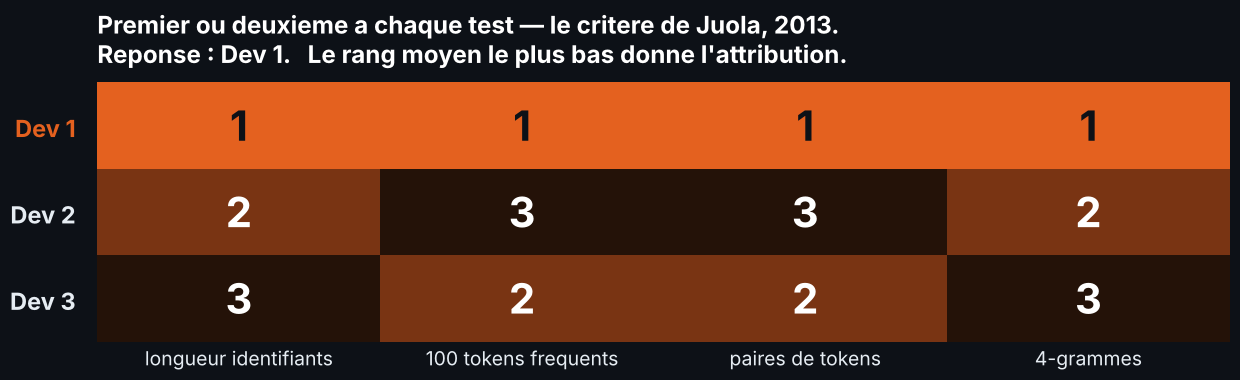

In [10]:
# ── LES 4 TESTS DE JUOLA, EN UNE IMAGE ──────────────────────────────
# Sequentiel : une seule teinte, clair = rang 1. Le rang est ECRIT dans la
# case — la couleur ne porte jamais l'information toute seule.
from matplotlib.colors import LinearSegmentedColormap
_cmap = LinearSegmentedColormap.from_list('rangs', ['#E4611F', '#7A3514', '#241208'])
_ordre = sorted(DEVS, key=lambda d: np.mean(rangs[d]))
_R = np.array([rangs[d] for d in _ordre], dtype=float)

fig, ax = scene(12.5, 3.9)
ax.grid(False)
ax.imshow(_R, cmap=_cmap, vmin=1, vmax=len(DEVS), aspect='auto')
for y in range(_R.shape[0]):
    for x in range(_R.shape[1]):
        ax.text(x, y, int(_R[y, x]), ha='center', va='center',
                fontsize=30, fontweight='bold',
                color='white' if _R[y, x] > 1 else FOND)
ax.set_xticks(range(len(TESTS)))
ax.set_xticklabels([n for n, _ in TESTS], color=ENCRE, fontsize=14)
ax.set_yticks(range(len(_ordre)))
ax.set_yticklabels([f'{d}   ' for d in _ordre], color=ENCRE, fontsize=17, fontweight='bold')
ax.get_yticklabels()[0].set_color(ACCENT)
for s in ax.spines.values(): s.set_visible(False)
ax.set_title("Premier ou deuxieme a chaque test — le critere de Juola, 2013.\n"
             f"Reponse : {_QUI}.   Le rang moyen le plus bas donne l'attribution.",
             color='white', fontsize=17.5, fontweight='bold', pad=14, loc='left')
ax.title.set_linespacing(1.7)
plt.tight_layout(); plt.show()

In [11]:
# ── ET SUR TOUS LES EXTRAITS POSSIBLES ───────────────────────────────
# Un seul extrait ne prouve rien. Chaque developpeur a 3 000 lignes : les
# 1 200 premieres servent de reference, il reste de quoi tailler quatre
# extraits de 400 lignes qui ne se chevauchent pas. Douze essais, pas un.
print('Quatre extraits de 400 lignes par developpeur, jamais vus par les references.')
print('Entre crochets : son rang aux quatre tests.\n')
bons = tot = 0; _pres, _loin = [0, 0], [0, 0]
for vrai in DEVS:
    ligne = []
    for n, a in enumerate(range(1300, len(CODE[vrai]) - 399, 400)):
        r = juola('\n'.join(CODE[vrai][a:a+400])); moy = {d: np.mean(r[d]) for d in DEVS}
        ok = min(moy, key=moy.get) == vrai
        bons += ok; tot += 1
        q = _pres if n == 0 else _loin
        q[0] += ok; q[1] += 1
        ligne.append(f"{'OK  ' if ok else 'RATE'} {r[vrai]}")
    print(f'  {vrai} :  ' + '   '.join(ligne))
print()
print(f'  {bons} sur {tot}.  Hasard : {tot // 3} sur {tot}.')
from math import comb as _comb
_p = sum(_comb(tot, k) * (1/3)**k * (2/3)**(tot - k) for k in range(bons, tot + 1))
print(f'  Pris seul, c est un indice : au hasard, {bons} bons ou plus arrivent {_p*100:.1f} % du temps.')
print(f'  L extrait qui suit juste les references : {_pres[0]} sur {_pres[1]}.')
print(f'  Les extraits ecrits plus tard           : {_loin[0]} sur {_loin[1]}.')
print()
if _pres[0] / _pres[1] > _loin[0] / _loin[1]:
    print('  La methode de 2013 trouve un signal sur du code. Mais regardez OU elle')
    print('  reussit : juste apres les references. Douze extraits, c est peu :')
    print('  retenez seulement qu elle reussit mieux de pres. L Acte 2 le mesure proprement.')
else:
    print('  La methode de 2013 trouve un signal sur du code, pres ou loin des references.')


Quatre extraits de 400 lignes par developpeur, jamais vus par les references.
Entre crochets : son rang aux quatre tests.



  Dev 1 :  OK   [1, 1, 1, 1]   OK   [1, 2, 1, 1]   OK   [1, 1, 1, 1]   OK   [1, 1, 1, 1]


  Dev 2 :  OK   [1, 1, 1, 1]   RATE [1, 3, 3, 3]   RATE [1, 2, 2, 2]   RATE [2, 2, 3, 2]
  Dev 3 :  OK   [3, 1, 1, 1]   RATE [2, 1, 1, 2]   OK   [1, 1, 1, 2]   RATE [3, 1, 1, 2]

  7 sur 12.  Hasard : 4 sur 12.
  Pris seul, c est un indice : au hasard, 7 bons ou plus arrivent 6.6 % du temps.
  L extrait qui suit juste les references : 3 sur 3.
  Les extraits ecrits plus tard           : 4 sur 9.

  La methode de 2013 trouve un signal sur du code. Mais regardez OU elle
  reussit : juste apres les references. Douze extraits, c est peu :
  retenez seulement qu elle reussit mieux de pres. L Acte 2 le mesure proprement.


In [12]:
# ── LA COURBE : COMBIEN DE CODE FAUT-IL ? ───────────────────────────
# Meme methode que les stylometres depuis 2002 — le Delta de Burrows : les 150
# tokens les plus frequents, un z-score par token, la distance de Manhattan.
# On decoupe le code des trois developpeurs en extraits de plus en plus longs
# et on regarde a partir de quelle taille on reconnait leur auteur.
_TOKC = {d: re.findall(r'[A-Za-z_]+|[^\sA-Za-z_]', '\n'.join(CODE[d])) for d in DEVS}
VOC = [w for w, _ in sum((Counter(t) for t in _TOKC.values()), Counter()).most_common(150)]
_PAR_LIGNE = sum(len(t) for t in _TOKC.values()) / sum(len(CODE[d]) for d in DEVS)

def precision_a(taille, tirages=30, seed=42):
    """Delta de Burrows a trois candidats. Renvoie (precision, nb d'extraits par dev)."""
    B = {d: [_TOKC[d][i:i+taille] for i in range(0, len(_TOKC[d]) - taille + 1, taille)] for d in DEVS}
    k = min(len(b) for b in B.values())
    if k < 6:
        return None, 0
    def _freq(bloc):
        c = Counter(bloc)                      # un seul comptage par extrait
        return [c[w] / taille for w in VOC]
    X = {d: np.array([_freq(b) for b in B[d][:k]]) for d in DEVS}
    pool = np.vstack(list(X.values())); mu = pool.mean(0); sd = pool.std(0); sd[sd == 0] = 1
    Z = {d: (X[d] - mu) / sd for d in DEVS}          # <- le "Delta"
    rng = np.random.default_rng(seed); ntr = max(2, int(k * 0.6)); scores = []
    for _ in range(tirages):
        idx = {d: rng.permutation(k) for d in DEVS}
        cen = {d: Z[d][idx[d][:ntr]].mean(0) for d in DEVS}
        bon = tot = 0
        for d in DEVS:
            for i in idx[d][ntr:]:
                dd = {e: np.abs(Z[d][i] - cen[e]).mean() for e in DEVS}
                bon += min(dd, key=dd.get) == d; tot += 1
        scores.append(bon / tot)
    return float(np.mean(scores)), k

# au-dela de 1 600 tokens il reste moins de 10 extraits par dev : trop bruite
TAILLES = [50, 100, 200, 400, 800, 1600]
PRECISION, NBLOCS = [], []
print()
print(f"{'tokens/extrait':>15} {'soit, en lignes':>16} {'extraits':>10} {'precision':>11}")
print('-' * 56)
for t in TAILLES:
    a, k = precision_a(t)
    PRECISION.append(a * 100); NBLOCS.append(k)
    print(f'{t:>15} {t / _PAR_LIGNE:>15.0f}  {k:>10} {a*100:>10.0f} %')
print('-' * 56)
print('hasard = 33 %   ·   3 developpeurs, un seul depot')



 tokens/extrait  soit, en lignes   extraits   precision
--------------------------------------------------------


             50               5         546         50 %


            100              10         273         55 %
            200              20         136         64 %
            400              39          68         71 %
            800              79          34         79 %
           1600             157          17         82 %
--------------------------------------------------------
hasard = 33 %   ·   3 developpeurs, un seul depot


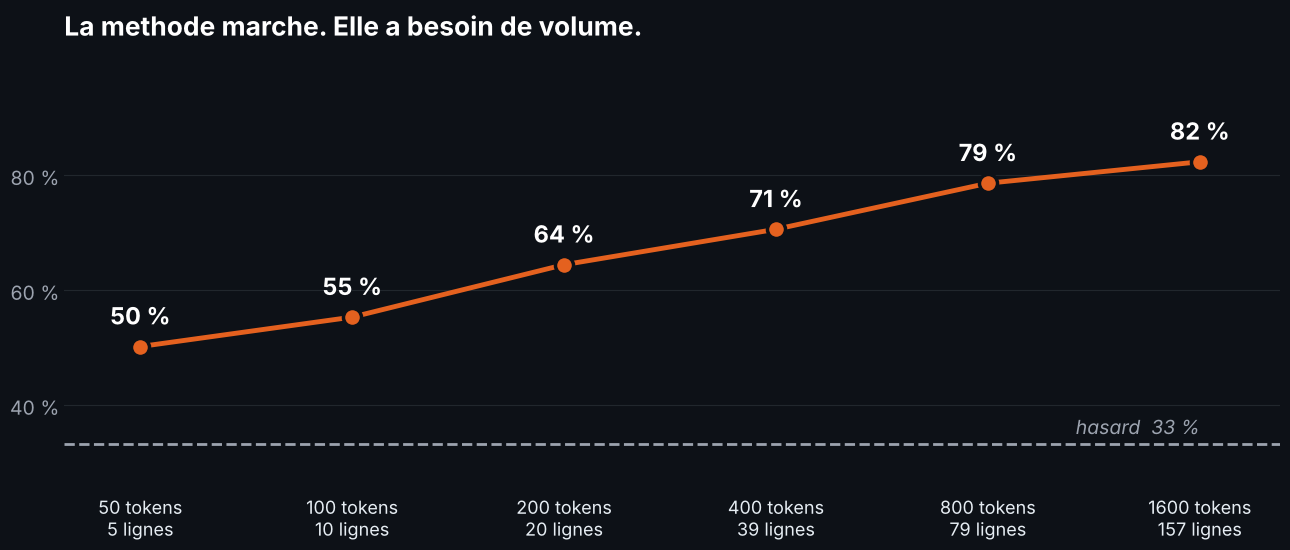

    5 lignes -> 50 %  : une fois sur deux, quand le hasard fait une sur trois
   20 lignes -> 64 %
  157 lignes -> 82 %

Cinq lignes ne disent rien de vous. Il en faut des dizaines, puis des centaines.


In [13]:
# ── LE GRAPHIQUE ─────────────────────────────────────────────────────
fig, ax = scene(13, 5.6)
ax.grid(False, axis='x'); ax.grid(True, axis='y', color=GRIS, lw=.8, alpha=.6)
ax.axhline(33.3, color=ENCRE2, ls='--', lw=2)
ax.text(TAILLES[-1], 35, 'hasard  33 %', color=ENCRE2, fontsize=14, style='italic', ha='right')
ax.plot(TAILLES, PRECISION, color=ACCENT, lw=3.5, marker='o', ms=13, mec=FOND, mew=2.5, zorder=5)
for x, y in zip(TAILLES, PRECISION):
    ax.annotate(f'{y:.0f} %', (x, y), textcoords='offset points', xytext=(0, 16), ha='center',
                color='white', fontsize=17, fontweight='bold')
ax.set_xscale('log'); ax.set_xticks(TAILLES); ax.minorticks_off()
ax.set_xlim(TAILLES[0] * .78, TAILLES[-1] * 1.3)
ax.set_xticklabels([f'{t} tokens\n{t / _PAR_LIGNE:.0f} lignes' for t in TAILLES], color=ENCRE, fontsize=13)
ax.set_ylim(25, 100); ax.set_yticks([40, 60, 80]); ax.set_yticklabels(['40 %', '60 %', '80 %'])
ax.set_title('La methode marche. Elle a besoin de volume.',
             color='white', fontsize=19, fontweight='bold', pad=18, loc='left')
plt.tight_layout(); plt.show()

_l = lambda t: f'{t / _PAR_LIGNE:.0f} lignes'
print(f'  {_l(TAILLES[0]):>10} -> {PRECISION[0]:.0f} %  : une fois sur deux, quand le hasard fait une sur trois')
print(f'  {_l(TAILLES[2]):>10} -> {PRECISION[2]:.0f} %')
print(f'  {_l(TAILLES[5]):>10} -> {PRECISION[5]:.0f} %')
print()
print('Cinq lignes ne disent rien de vous. Il en faut des dizaines, puis des centaines.')


### ✅ Acte 1 — message transmis

---

**🎙️**
> *"OK. Donc on peut mesurer un style humain.*
> *Mais un score élevé mesure-t-il toujours ce qu'on croit ?"*

---
---


---

## 🔴 LIVE 2 — Le modèle apprend-il l'auteur, ou le sujet ?

**🎙️** *"PAN 2020 classe la dépendance au sujet parmi les principales causes d'erreur.*
*Au lieu de vous le citer, je vais vous le montrer."*

On entraîne **deux** classifieurs sur les mêmes 4 auteurs :
l'un sur des **mots de contenu**, l'autre sur des **mots-fonction**.


In [14]:
# ── DEUX CLASSIFIEURS, MÊMES AUTEURS ─────────────────────────────────
# Ici, et seulement ici, on quitte le code : il faut des AUTEURS qui racontent
# des HISTOIRES differentes pour voir un classifieur apprendre le sujet.
# Quatre romans du domaine public, preambules d'editeur retires
# (experiments/nettoyer_romans.py).
AUTEURS = {'Zola':'corpus/zola_germinal.txt','Maupassant':'corpus/maupassant_boule_de_suif.txt',
           'Flaubert':'corpus/flaubert_madame_bovary.txt','Verne':'corpus/verne_tour_du_monde.txt'}
def charger(chemin):
    txt=open(chemin,encoding='utf-8').read()
    txt='\n'.join(l for l in txt.split('\n') if not l.startswith('#'))
    return re.findall(r'[a-zA-Z]+', txt.lower())
T={a:charger(pth) for a,pth in AUTEURS.items()}
for a in AUTEURS: print(f'  {a:12s} {len(T[a]):>7,} mots')
print()

FONCTIONNELS = set(('le la les un une des de du et ou mais donc ni car que qui dans sur '
                    'avec sans pour par il elle ils elles je tu nous vous ne pas plus tres '
                    'bien tout tous rien ce se son sa ses leur a au aux en y d l s c n j m t '
                    'qu est etait sont ete avoir etre fait').split())
# « comme » et « cette » ne sont pas dans la liste ci-dessus, mais ce sont des mots
# grammaticaux : on les ecarte aussi du vocabulaire de CONTENU (audit du 3 novembre 2026).
GRAMMATICAUX = FONCTIONNELS | {'comme', 'cette'}

_n = min(len(t) for t in T.values())
TT = {a: T[a][:_n] for a in AUTEURS}
_pool = Counter(sum(TT.values(), []))

VOC_CONTENU  = [w for w, _ in _pool.most_common(600)
                if w not in GRAMMATICAUX and len(w) > 3][:60]
VOC_FONCTION = [w for w, _ in _pool.most_common(400) if w in FONCTIONNELS][:60]

def _freq(tk, voc):
    n = len(tk); c = Counter(tk)
    return np.array([c.get(w, 0)/n for w in voc])

def _vec(tk, voc):
    v = _freq(tk, voc); k = np.linalg.norm(v)
    return v/k if k > 0 else v

def precision(voc, tirages=20, seed=3):
    rng = np.random.default_rng(seed); accs = []
    for _ in range(tirages):
        cent = {}; tests = []
        for a in AUTEURS:
            b = [TT[a][i:i+1000] for i in range(0, len(TT[a])-999, 1000)]
            h = len(b)//2
            idx = rng.permutation(h)[:max(4, h//2)]
            cent[a] = np.mean([_vec(b[i], voc) for i in idx], axis=0)
            for j in rng.permutation(range(h, len(b)))[:6]:
                tests.append((a, _vec(b[j], voc)))
        ok = sum(1 for vrai, v in tests
                 if min(cent, key=lambda x: 1-np.dot(v, cent[x])) == vrai)
        accs.append(ok/len(tests))
    return float(np.mean(accs))

p_contenu  = precision(VOC_CONTENU)
p_fonction = precision(VOC_FONCTION)

print('Attribution sur 4 auteurs, extraits de 1 000 mots tenus a l ecart :')
print('-' * 58)
print(f'  mots de CONTENU   {p_contenu*100:5.0f} %   {"#"*int(p_contenu*34)}')
print(f'  mots-FONCTION     {p_fonction*100:5.0f} %   {"#"*int(p_fonction*34)}')
print('-' * 58)
print(f'  hasard             {25:5.0f} %')
print()
print('Sur CE protocole, le classifieur sur les mots de contenu est nettement')
print('meilleur. Le vocabulaire est choisi sur tout le corpus, test compris :')
print('ce n est pas un protocole etanche, c est une demonstration.')
print('On le garde, alors ? Regardons d abord ce qu il a appris.')

  Zola          36,333 mots
  Maupassant    36,271 mots
  Flaubert      36,139 mots
  Verne         31,057 mots



Attribution sur 4 auteurs, extraits de 1 000 mots tenus a l ecart :
----------------------------------------------------------
  mots de CONTENU      72 %   ########################
  mots-FONCTION        61 %   ####################
----------------------------------------------------------
  hasard                25 %

Sur CE protocole, le classifieur sur les mots de contenu est nettement
meilleur. Le vocabulaire est choisi sur tout le corpus, test compris :
ce n est pas un protocole etanche, c est une demonstration.
On le garde, alors ? Regardons d abord ce qu il a appris.


In [15]:
# ── CE QUE CHAQUE CLASSIFIEUR A RÉELLEMENT APPRIS ────────────────────
def discriminants(voc, k=6):
    M = np.array([_freq(TT[a], voc) for a in AUTEURS])
    noms = list(AUTEURS)
    ecart = M.max(axis=0) - M.min(axis=0)
    return [(voc[i], noms[int(np.argmax(M[:, i]))])
            for i in np.argsort(ecart)[::-1][:k]]

print(f'MOTS DE CONTENU — le classifieur a {p_contenu*100:.0f} %')
print('-' * 48)
for w, a in discriminants(VOC_CONTENU):
    print(f'   {w:18s} -> {a}')
print()
print(f'MOTS-FONCTION — le classifieur a {p_fonction*100:.0f} %')
print('-' * 48)
for w, a in discriminants(VOC_FONCTION):
    print(f'   {w:18s} -> {a}')
print()
print('=' * 58)
print('  Le meilleur classifieur a appris des NOMS DE PERSONNAGES.')
print('  Il ne reconnait pas Verne. Il reconnait Phileas Fogg.')
print()
print('  Ma prediction, NON mesuree : un autre roman de Verne, sans Fogg,')
print('  et il s effondre. Un seul roman par auteur ici.')
print('  PAN 2020 classe la dependance au sujet parmi les principales')
print('  causes d erreur (Kestemont et al. 2020, section 8).')
print('=' * 58)
print()
print("=" * 60)
print("  PIEGE 1 / 4   —   \"le sujet deguise\"")
print("  fogg, passepartout : le classifieur a appris le theme")
print("=" * 60)

MOTS DE CONTENU — le classifieur a 72 %
------------------------------------------------
   fogg               -> Verne
   passepartout       -> Verne
   phileas            -> Verne
   charles            -> Flaubert
   heures             -> Verne
   repondit           -> Verne

MOTS-FONCTION — le classifieur a 61 %
------------------------------------------------
   elle               -> Flaubert
   la                 -> Zola
   des                -> Flaubert
   a                  -> Verne
   les                -> Flaubert
   le                 -> Verne

  Le meilleur classifieur a appris des NOMS DE PERSONNAGES.
  Il ne reconnait pas Verne. Il reconnait Phileas Fogg.

  Ma prediction, NON mesuree : un autre roman de Verne, sans Fogg,
  et il s effondre. Un seul roman par auteur ici.
  PAN 2020 classe la dependance au sujet parmi les principales
  causes d erreur (Kestemont et al. 2020, section 8).

  PIEGE 1 / 4   —   "le sujet deguise"
  fogg, passepartout : le classifieur a appris l

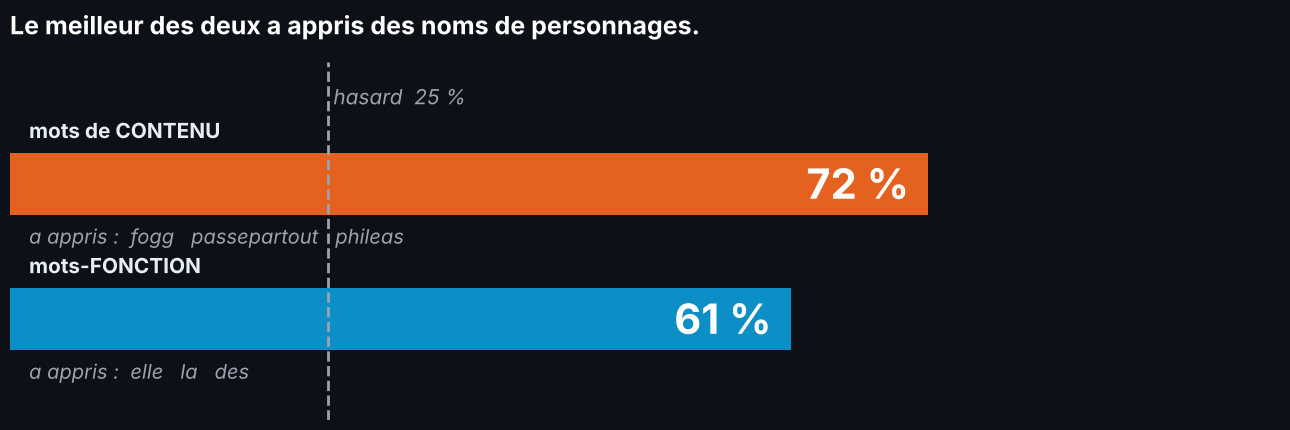

In [16]:
# ── LE PIEGE N.1, EN UNE IMAGE ──────────────────────────────────────
# La barre la plus haute a appris des noms de personnages. On le lit
# sous la barre, pas dans un tableau separe.
fig, ax = scene(13, 4.4)
_v = [p_contenu * 100, p_fonction * 100]
ax.barh([1, 0], _v, height=.46, color=[ACCENT, BLEU], zorder=3)
ax.axvline(25, color=ENCRE2, ls='--', lw=2, zorder=4)
ax.text(25, 1.55, ' hasard  25 %', color=ENCRE2, fontsize=15, style='italic', va='bottom')
for y, v in zip([1, 0], _v):
    ax.text(v - 1.5, y, f'{v:.0f} %', color='white', fontsize=30, fontweight='bold',
            va='center', ha='right', zorder=5)
for y, (lbl, voc) in zip([1, 0], [('mots de CONTENU', VOC_CONTENU),
                                  ('mots-FONCTION', VOC_FONCTION)]):
    ax.text(1.5, y + .30, lbl, color=ENCRE, fontsize=15, fontweight='bold', va='bottom')
    ax.text(1.5, y - .30, 'a appris :  ' + '   '.join(w for w, _ in discriminants(voc, 3)),
            color=ENCRE2, fontsize=14.5, va='top', style='italic')
ax.set_yticks([]); ax.set_xticks([]); ax.set_xlim(0, 100); ax.set_ylim(-.75, 1.9)
ax.set_title("Le meilleur des deux a appris des noms de personnages.",
             color='white', fontsize=18, fontweight='bold', pad=20, loc='left')
plt.tight_layout(); plt.show()

---

### ⚠️ Et sur de vrais développeurs ?

**🎙️** *"Et maintenant la question honnête : est-ce que ça marche sur du vrai code ?*
*Trois contributeurs réels de Django. Les dix mesures lisibles, je les détaille au Live 3."*

Corpus : `corpus/devs/` — lignes réellement ajoutées par chacun. La règle d'extraction
est dans `experiments/construire_corpus.py`, et elle a été fixée avant de regarder un score.


In [17]:
# ── DIX FEATURES LISIBLES, SUR DE VRAIS DÉVELOPPEURS ─────────────────
# 3 contributeurs d'UN SEUL depot (django/django), anonymises.
# Corpus controle : meme epoque, meme type de code, commits de 300 lignes au
# plus — experiments/construire_corpus.py. Ce n'etait pas le premier corpus.
# Les 10 features lisibles (sig) sont montrees en clair au Live 3, cellule
# « LES 10 FEATURES, EN CLAIR ». Ici, on prend la meme fonction dans experiments/.
if 'experiments' not in sys.path: sys.path.insert(0, 'experiments')
from _commun import sig

DEVS = {f'Dev {i}': f'corpus/devs/dev_{i}.py' for i in range(1, 4)}

def charger_code(chemin):
    return [l for l in open(chemin, encoding='utf-8').read().split('\n')
            if l.strip() and not l.startswith('# Lignes ajoutees')
            and not l.startswith('# Extraites')]

CODE = {d: charger_code(p) for d, p in DEVS.items()}
for d in DEVS:
    print(f'  {d} : {len(CODE[d]):,} lignes reellement ajoutees'.replace(',', ' '))

# ── PIEGE 2 / 4 — a l'ecran, plus en commentaire ────────────────────
# Les chiffres ci-dessous ne se recalculent pas ici : il faut un clone de
# flask. Ils sortent tous de experiments/pourquoi_pas_flask.py.
print()
print('=' * 68)
print('  PIEGE 2 / 4   —   « le label » : ce qu il cachait')
print('=' * 68)
print('  git log --author donne le COMMITTEUR, pas l auteur du code.')
print()
print('  Mon PREMIER corpus venait d un autre depot, pallets/flask.')
print('  Un candidat y avait :')
print(f'      {3788:>6,} lignes sur {3796:,}'.replace(',', ' ')
      + f'  —  soit {3788/3796*100:.1f} %  —')
print('      dans UN SEUL commit : « Reformat with black ».')
print('  Quatrieme contributeur du depot par le volume. Techniquement, un script.')
print()
print('  Je l ai ecarte. Ca ne suffisait pas. Des trois qui restaient :')
print('      l un avait 92 % de ses lignes APRES l adoption de black par le projet ;')
print('      un autre en avait 90 % dans tests/.')
print('  Et le meme developpeur — sa bibliotheque contre ses tests — se separait')
print('  de LUI-MEME a 100 %. Ce corpus affichait pres de 90 % d attribution :')
print('  voila ce que ca mesurait.')
print('=' * 68)
print()
print('  J ai jete ce corpus. Celui-ci vient de django, avec trois regles :')
print('  meme epoque, meme type de code, commits de 300 lignes au plus.')
print('  A rejouer chez vous : experiments/pourquoi_pas_flask.py')

def blocs_code(L, n):
    return ['\n'.join(L[i:i+n]) for i in range(0, len(L)-n+1, n)]

  Dev 1 : 3 000 lignes reellement ajoutees
  Dev 2 : 3 000 lignes reellement ajoutees
  Dev 3 : 3 000 lignes reellement ajoutees

  PIEGE 2 / 4   —   « le label » : ce qu il cachait
  git log --author donne le COMMITTEUR, pas l auteur du code.

  Mon PREMIER corpus venait d un autre depot, pallets/flask.
  Un candidat y avait :
       3 788 lignes sur 3 796  —  soit 99.8 %  —
      dans UN SEUL commit : « Reformat with black ».
  Quatrieme contributeur du depot par le volume. Techniquement, un script.

  Je l ai ecarte. Ca ne suffisait pas. Des trois qui restaient :
      l un avait 92 % de ses lignes APRES l adoption de black par le projet ;
      un autre en avait 90 % dans tests/.
  Et le meme developpeur — sa bibliotheque contre ses tests — se separait
  de LUI-MEME a 100 %. Ce corpus affichait pres de 90 % d attribution :
  voila ce que ca mesurait.

  J ai jete ce corpus. Celui-ci vient de django, avec trois regles :
  meme epoque, meme type de code, commits de 300 lignes au plus

In [18]:
# ── LA MESURE, SUR DONNEES PROPRES ──────────────────────────────────
def precision_code(taille, tirages=20, seed=7):
    B = {d: blocs_code(CODE[d], taille) for d in DEVS}
    k = min(len(B[d]) for d in DEVS)
    if k < 8: return None, 0
    X = {d: np.array([sig(b) for b in B[d][:k]]) for d in DEVS}
    pool = np.vstack([X[d] for d in DEVS]); mu = pool.mean(0); sd = pool.std(0); sd[sd==0]=1
    Z = {d: (X[d]-mu)/sd for d in DEVS}
    rng = np.random.default_rng(seed); ntr = max(2, int(k*0.6)); accs = []
    for _ in range(tirages):
        idx = {d: rng.permutation(k) for d in DEVS}
        cen = {d: Z[d][idx[d][:ntr]].mean(0) for d in DEVS}
        ok = t = 0
        for d in DEVS:
            for i in idx[d][ntr:]:
                dd = {e: np.abs(Z[d][i]-cen[e]).mean() for e in DEVS}
                ok += min(dd, key=dd.get) == d; t += 1
        accs.append(ok/t)
    return float(np.mean(accs)), k

print()
print(f"{'lignes/bloc':>12} {'blocs/dev':>11} {'precision':>11}   (hasard = 33 %)")
print('-' * 52)
_PREC_LIS = {}
for n in [20, 40, 80, 160, 320]:
    a, k = precision_code(n)
    if a is None: continue
    _PREC_LIS[n] = a
    print(f'{n:>12} {k:>11,} {a*100:>10.0f} %   {"#"*int(a*30)}')
print('-' * 52)


 lignes/bloc   blocs/dev   precision   (hasard = 33 %)
----------------------------------------------------
          20         150         50 %   ###############


          40          75         53 %   ###############
          80          37         58 %   #################
         160          18         58 %   #################
         320           9         60 %   ##################
----------------------------------------------------


In [19]:
# ╔═══════════════════════════════════════════════════════════════════╗
# ║  HORS DU SPEECH DE 40 MINUTES — a sauter, sauf si tu as de l avance.║
# ║  Le texte qui va avec est dans la version longue du speech.       ║
# ╚═══════════════════════════════════════════════════════════════════╝
# ── SI BAS, COMPARE A QUOI ? ────────────────────────────────────────
print()
print('Mes trois profils        : 3 sur 3.')
_mx = max(_PREC_LIS.values()) * 100
print(f'Trois developpeurs reels : {_PREC_LIS[160] * 100:.0f} % a 160 lignes, {_mx:.0f} % au mieux, hasard a 33 %.')
print()
print(f'Au mieux {_mx / 33.3:.1f} fois le hasard. Mes features lisibles ne suffisent pas.')
print()
print('A COMPARER A QUOI ? Caliskan obtient 94 % sur 1 600 auteurs — sur Google')
print('Code Jam, ou chaque fichier a exactement un auteur.')
print('Un depot partage ne ressemble pas a ca. Sur psf/requests (clone complet) :')
print('mediane de 9 auteurs par fichier, record a 122 ; dans le fichier median,')
print('l auteur principal ne detient que 49 % des lignes.')
print()
print('Ce n est pas l explication de mes chiffres : mon corpus compte des LIGNES')
print('ajoutees par chacun, pas des fichiers. C est la raison de ne pas comparer')
print('mes chiffres aux siens.')
print()


Mes trois profils        : 3 sur 3.
Trois developpeurs reels : 58 % a 160 lignes, 60 % au mieux, hasard a 33 %.

Au mieux 1.8 fois le hasard. Mes features lisibles ne suffisent pas.

A COMPARER A QUOI ? Caliskan obtient 94 % sur 1 600 auteurs — sur Google
Code Jam, ou chaque fichier a exactement un auteur.
Un depot partage ne ressemble pas a ca. Sur psf/requests (clone complet) :
mediane de 9 auteurs par fichier, record a 122 ; dans le fichier median,
l auteur principal ne detient que 49 % des lignes.

Ce n est pas l explication de mes chiffres : mon corpus compte des LIGNES
ajoutees par chacun, pas des fichiers. C est la raison de ne pas comparer
mes chiffres aux siens.



---

### Et si on voulait faire mieux — honnêtement ?

**🎙️** *"Moins de deux fois le hasard, c'est décevant. Mais ce n'est pas la méthode*
*qui est en cause — ce sont mes features. J'ai choisi dix mesures à la main*
*parce qu'elles sont pédagogiques. Voyons ce que donne l'état de l'art."*


In [20]:
# ── CE QUI FERAIT MIEUX, MESURÉ SUR LES MÊMES DONNÉES ────────────────
# Mes 10 features sont lisibles — camelCase, type hints, == None.
# L'état de l'art ne fait pas ça : il prend des n-grammes de caractères,
# illisibles un par un, mais qui capturent la mise en forme, les idiomes,
# l'espacement, les habitudes de nommage — tout à la fois.

_ALL = '\n'.join('\n'.join(CODE[d]) for d in DEVS)
_VOC4 = [g for g, _ in Counter(_ALL[i:i+4] for i in range(len(_ALL)-3)).most_common(800)]

def sig_ngrammes(src):
    c = Counter(src[i:i+4] for i in range(len(src)-3)); n = max(len(src)-3, 1)
    return [c.get(g, 0)/n for g in _VOC4]

def precision_avec(f, taille, tirages=20, seed=7):
    B = {d: blocs_code(CODE[d], taille) for d in DEVS}
    k = min(len(B[d]) for d in DEVS)
    if k < 8: return None
    X = {d: np.array([f(b) for b in B[d][:k]]) for d in DEVS}
    pool = np.vstack([X[d] for d in DEVS]); mu = pool.mean(0); sd = pool.std(0); sd[sd==0]=1
    Z = {d: (X[d]-mu)/sd for d in DEVS}
    rng = np.random.default_rng(seed); ntr = max(2, int(k*0.6)); acc = []
    for _ in range(tirages):
        idx = {d: rng.permutation(k) for d in DEVS}
        cen = {d: Z[d][idx[d][:ntr]].mean(0) for d in DEVS}
        ok = t = 0
        for d in DEVS:
            for i in idx[d][ntr:]:
                dd = {e: np.abs(Z[d][i]-cen[e]).mean() for e in DEVS}
                ok += min(dd, key=dd.get) == d; t += 1
        acc.append(ok/t)
    return float(np.mean(acc))

TAILLES_C = [80, 160]   # au-dela, moins de 8 blocs par dev
print(f"{'':<30}" + ''.join(f'{str(t)+" lignes":>13}' for t in TAILLES_C))
print('-' * 70)
for nom, f in [('mes 10 features lisibles', sig),
               ('4-grammes de caracteres', sig_ngrammes)]:
    r = [precision_avec(f, t) for t in TAILLES_C]
    print(f'  {nom:<28}' + ''.join(f'{(x*100 if x else 0):>11.0f} %' for x in r))
print('-' * 70)
print('  hasard : 33 %')
print()
_l160, _n160 = precision_avec(sig, 160) * 100, precision_avec(sig_ngrammes, 160) * 100
print(f'De {_l160:.0f} a {_n160:.0f} pour cent, AVEC CE DECOUPAGE.')
print('Memes developpeurs, memes blocs : seules les features changent.')
print()
print('CE QUE CA COUTE : on perd l explication. Je peux vous dire pourquoi')
print('un fichier est attribue a Dev A avec mes 10 features — camelCase,')
print('== None. Avec huit cents n-grammes, je ne peux plus.')
print()
print('Et plus la consequence de la mesure est lourde, plus il faut pouvoir')
print('expliquer ce qu elle etablit reellement.')
print('C est le compromis de PAN 2020 : weerasinghe a fait 0.902 avec des features')
print('stylometriques (mots-fonction, richesse du vocabulaire, n-grammes)')
print('avec des features explicables, et il est arrive deuxieme.')

                                  80 lignes   160 lignes
----------------------------------------------------------------------


  mes 10 features lisibles             58 %         58 %


  4-grammes de caracteres              72 %         84 %
----------------------------------------------------------------------
  hasard : 33 %



De 58 a 84 pour cent, AVEC CE DECOUPAGE.
Memes developpeurs, memes blocs : seules les features changent.

CE QUE CA COUTE : on perd l explication. Je peux vous dire pourquoi
un fichier est attribue a Dev A avec mes 10 features — camelCase,
== None. Avec huit cents n-grammes, je ne peux plus.

Et plus la consequence de la mesure est lourde, plus il faut pouvoir
expliquer ce qu elle etablit reellement.
C est le compromis de PAN 2020 : weerasinghe a fait 0.902 avec des features
stylometriques (mots-fonction, richesse du vocabulaire, n-grammes)
avec des features explicables, et il est arrive deuxieme.


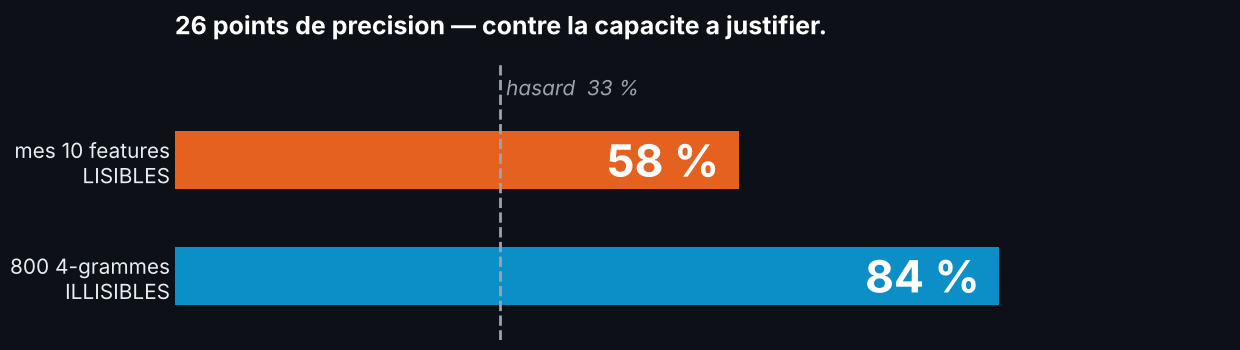

In [21]:
# ── LE COMPROMIS, EN UNE IMAGE ──────────────────────────────────────
_lis = precision_avec(sig, 160)
_ngr = precision_avec(sig_ngrammes, 160)
fig, ax = scene(12.5, 3.6)
_n = ['mes 10 features\nLISIBLES', '800 4-grammes\nILLISIBLES']
_v = [_lis * 100, _ngr * 100]
ax.barh([1, 0], _v, height=.5, color=[ACCENT, BLEU], zorder=3)
ax.axvline(33.3, color=ENCRE2, ls='--', lw=2, zorder=4)
ax.text(33.3, 1.52, ' hasard  33 %', color=ENCRE2, fontsize=15, style='italic', va='bottom')
for y, v in zip([1, 0], _v):
    ax.text(v - 2, y, f'{v:.0f} %', color='white', fontsize=32, fontweight='bold',
            va='center', ha='right', zorder=5)
ax.set_yticks([1, 0]); ax.set_yticklabels(_n, color=ENCRE, fontsize=15)
ax.set_xlim(0, 108); ax.set_xticks([]); ax.set_ylim(-.55, 1.85)
ax.set_title(f"{round(_v[1]) - round(_v[0])} points de precision — contre la capacite a justifier.",
             color='white', fontsize=18, fontweight='bold', pad=20, loc='left')
plt.tight_layout(); plt.show()

In [22]:
# ── CONTRE-TEST DES 4-GRAMMES — protocole complet, execute en direct ─
# Ce score, je l'ai attaque. Deux fuites possibles, testees separement :
#   1. PROXIMITE DES BLOCS — blocs contigus melanges au hasard entre train
#      et test. Contre-protocole : split CONTIGU, les 60 % premiers blocs en
#      apprentissage, les 40 % derniers en test. Des mois de commits entre.
#   2. VOCABULAIRE — les 800 4-grammes choisis sur tout le corpus, test
#      compris. Contre-protocole : choisis sur le TRAIN SEUL.
# Le script affiche les 4 combinaisons, chiffre chaque fuite, et conclut
# tout seul : la phrase finale depend des chiffres, pas de moi.
import subprocess, sys as _s
_r = subprocess.run([_s.executable, 'experiments/fuite_blocs.py', '--court'],
                    capture_output=True, text=True)
print(_r.stdout if _r.returncode == 0 else 'LE CONTRE-TEST A ECHOUE :\n' + _r.stderr)


CONTRE-TEST DES 4-GRAMMES — LE SCORE TIENT-IL A UNE FUITE ?

  colonne 1 : alea + vocabulaire sur tout  =  LE PROTOCOLE DU NOTEBOOK
  colonne 2 : split contigu  — des mois de commits entre train et test
  colonne 3 : vocabulaire choisi sur le train seul
  colonne 4 : les deux corrections a la fois

 bloc blocs train   NOTEBOOK  contigu  voc.train  les deux
--------------------------------------------------------------
   40    75    45        73%      60%        73%       54%
   60    50    30        72%      63%        69%       50%
   80    37    22        76%      62%        76%       51%
  120    25    15        78%      67%        75%       63%
  160    18    10        84%      67%        83%       62%
--------------------------------------------------------------
hasard : 33 %   ·   800 4-grammes de caracteres   ·   3 devs, 1 depot

  FUITE 1, proximite des blocs  (col.2 - col.1) : -12.8 points en
  moyenne, de -17.3 a -8.3.
  Separer le train du test dans le temps FAIT tomber le

In [23]:
# ╔═══════════════════════════════════════════════════════════════════╗
# ║  HORS DU SPEECH DE 40 MINUTES — le resultat est sur la slide 10.  ║
# ║  A lancer si on te demande le detail (11 secondes de calcul).     ║
# ╚═══════════════════════════════════════════════════════════════════╝
# ── FAIRE MIEUX SANS TRICHER ────────────────────────────────────────
# La methode est choisie sur les 60 % de commits ANCIENS seulement, puis
# testee UNE fois sur les 40 % recents. Protocole ecrit et commite avant
# la premiere execution : en tete de experiments/ameliorer.py.
import subprocess, sys as _s
_r = subprocess.run([_s.executable, 'experiments/ameliorer.py'], capture_output=True, text=True)
_out = _r.stdout if _r.returncode == 0 else 'ECHEC :\n' + _r.stderr
print('\n'.join(l for l in _out.split('\n') if not l.startswith('     ') and not l.startswith('    >')))
print('Le detail de TOUTES les methodes essayees : python3 experiments/ameliorer.py')


BLOCS DE 80 LIGNES — TOUTES LES FEATURES   (validation : 27 decisions, test : 45)
  RETENUE SUR LA VALIDATION : 800 3-grammes, brut + cosinus  (validation 89 %)
  TEST, UNE SEULE FOIS      : 24/45 = 53 %   IC 95 % [39 ; 67]   hasard 33 %
  reference du talk (800 4-grammes, z + Manhattan) au test : 56 %
  reference du talk (10 lisibles, z + Manhattan) au test    : 67 %
  toutes les methodes essayees (validation -> test) :

BLOCS DE 80 LIGNES — FEATURES EXPLICABLES SEULEMENT   (validation : 27 decisions, test : 45)
  RETENUE SUR LA VALIDATION : 100 tokens, z + Manhattan  (validation 74 %)
  TEST, UNE SEULE FOIS      : 31/45 = 69 %   IC 95 % [54 ; 80]   hasard 33 %
  reference du talk (10 lisibles, z + Manhattan) au test    : 67 %
  toutes les methodes essayees (validation -> test) :

BLOCS DE 160 LIGNES — TOUTES LES FEATURES   (validation : 12 decisions, test : 21)
  RETENUE SUR LA VALIDATION : 800 4-grammes, z + Manhattan  (validation 100 %)
  TEST, UNE SEULE FOIS      : 13/21 = 62 %   

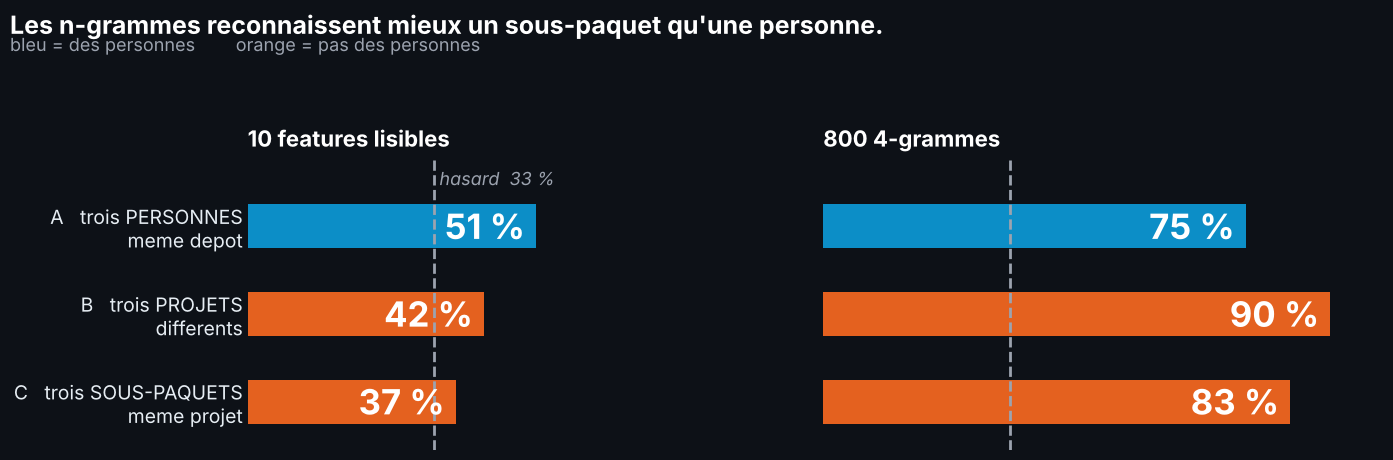

  15 blocs de 80 lignes par candidat partout, 7 graines.
  Features lisibles : personnes 51 %, projets 42 %, sous-paquets 37 %.
  4-grammes         : personnes 75 %, projets 90 %, sous-paquets 83 %.

  Avec les n-grammes, trois sous-paquets d un meme projet — aucune personne
  la-dedans, seulement trois sujets — se separent MIEUX que trois personnes.
  Avec les features lisibles, non : elles ne reconnaissent pas un projet.

  PIEGE 3 / 4 : un score eleve peut venir du PROJET, pas de la personne.
  Plus la mesure est puissante, plus elle apprend le code qu elle a sous
  les yeux. Script : experiments/piege_projet.py


In [24]:
# ── PIEGE 3 / 4 — « LE PROJET » ─────────────────────────────────────
# Un score eleve prouve-t-il qu'on reconnait une PERSONNE ? Trois conditions,
# meme protocole, MEME nombre de blocs partout :
#   A  trois PERSONNES, meme depot
#   B  trois PROJETS differents (django / requests / PyYAML)
#   C  trois SOUS-PAQUETS d'un meme projet — aucune personne : le temoin
import sys
sys.path.insert(0, 'experiments')
from piege_projet import precision as _prec, blocs as _blocs, contributeurs, corpus_projet, corpus_temoin
from _commun import precision as _prec_ng

_A = contributeurs()
_B = {'django Dev 1': _A['Dev 1'], 'requests': corpus_projet('requests'),
      'PyYAML': corpus_projet('pyyaml')}
_C = {'werkzeug/sansio': corpus_temoin('sansio'), 'werkzeug/routing': corpus_temoin('routing'),
      'werkzeug/debug': corpus_temoin('debug')}
_T, _G = 80, [7, 11, 23, 42, 101, 2024, 31337]
_k = min(min(len(_blocs(v, _T)) for v in D.values()) for D in (_A, _B, _C))
_lis = {l: float(np.mean([_prec(D, taille=_T, graine=g, kmax=_k)[0] * 100 for g in _G]))
        for l, D in zip('ABC', (_A, _B, _C))}
_ngr = {l: _prec_ng({d: x[:_k * _T] for d, x in D.items()}, _T, 'ngrammes')[0]
        for l, D in zip('ABC', (_A, _B, _C))}

# deux facettes, meme echelle : la couleur dit « des personnes » ou « pas des personnes »
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), sharex=True)
fig.patch.set_facecolor(FOND)
_noms = ['A   trois PERSONNES\nmeme depot', 'B   trois PROJETS\ndifferents',
         'C   trois SOUS-PAQUETS\nmeme projet']
for ax, (titre, R) in zip(axes, (('10 features lisibles', _lis), ('800 4-grammes', _ngr))):
    ax.set_facecolor(FOND)
    for sp in ax.spines.values(): sp.set_visible(False)
    ax.barh([2, 1, 0], [R['A'], R['B'], R['C']], height=.5, color=[BLEU, ACCENT, ACCENT], zorder=3)
    ax.axvline(33.3, color=ENCRE2, ls='--', lw=2, zorder=4)
    for y, l in zip([2, 1, 0], 'ABC'):
        ax.text(R[l] - 2, y, f'{R[l]:.0f} %', color='white', fontsize=25, fontweight='bold',
                va='center', ha='right', zorder=5)
    ax.set_xlim(0, 100); ax.set_xticks([]); ax.set_ylim(-.55, 2.75); ax.tick_params(length=0)
    ax.set_yticks([2, 1, 0])
    ax.set_yticklabels(_noms if ax is axes[0] else ['', '', ''], color=ENCRE, fontsize=14)
    ax.set_title(titre, color='white', fontsize=16, fontweight='bold', pad=10, loc='left')
axes[0].text(33.3, 2.42, ' hasard  33 %', color=ENCRE2, fontsize=13, style='italic', va='bottom')
_piege = _ngr['C'] > _ngr['A'] + 5
fig.suptitle("Les n-grammes reconnaissent mieux un sous-paquet qu'une personne." if _piege
             else 'Personnes, projets, sous-paquets : qui se separe le mieux ?',
             color='white', fontsize=18, fontweight='bold', x=.008, ha='left', y=.99)
fig.text(.008, .9, 'bleu = des personnes        orange = pas des personnes',
         color=ENCRE2, fontsize=13, ha='left')
plt.tight_layout(rect=[0, 0, 1, .87]); plt.show()

print(f'  {_k} blocs de {_T} lignes par candidat partout, {len(_G)} graines.')
print(f"  Features lisibles : personnes {_lis['A']:.0f} %, projets {_lis['B']:.0f} %, sous-paquets {_lis['C']:.0f} %.")
print(f"  4-grammes         : personnes {_ngr['A']:.0f} %, projets {_ngr['B']:.0f} %, sous-paquets {_ngr['C']:.0f} %.")
print()
if _piege:
    print('  Avec les n-grammes, trois sous-paquets d un meme projet — aucune personne')
    print('  la-dedans, seulement trois sujets — se separent MIEUX que trois personnes.')
    if _lis['B'] <= _lis['A'] and _lis['C'] <= _lis['A']:
        print('  Avec les features lisibles, non : elles ne reconnaissent pas un projet.')
    print()
    print('  PIEGE 3 / 4 : un score eleve peut venir du PROJET, pas de la personne.')
    print('  Plus la mesure est puissante, plus elle apprend le code qu elle a sous')
    print('  les yeux. Script : experiments/piege_projet.py')
else:
    print('  Sur ces corpus, le projet ne se separe pas mieux que la personne.')


### ✅ Acte 2 — message transmis

---

**🎙️**
> *"Donc le style se mesure — à condition de vérifier ce que le chiffre a appris.*
> *Et quand c'est une IA qui écrit ?"*

---
---

---
---
# ACTE 3 — Et quand ce n'est plus vous qui écrivez ?

**Timing : 20:45 → 38:45**

**Live 3 en 3 temps** — profils → bar chart → attribution fichier par fichier.
L'attribution utilise `afficher()` / `révéler()` — la salle vote entre les deux.

---

## Le pivot

> *"Même technique. Autre domaine."*

Ce qui trahit un auteur dans un roman — ce qu'il écrit sans y penser —
existe aussi dans son code. Et la machine, elle aussi, écrit sans y penser.

---

## 🔴 LIVE 3 — Votre code aussi a une empreinte

**Timing : 22:15 → 26:30 (4 min max)**

**🎙️** *"Même technique. Autre domaine.*
*Votre camelCase, vos type hints, vos commentaires —*
*c'est votre style. Et l'assistant a le sien."*

**🎙️ (à la fin du live)** *"Le script est dans le dépôt :*
*`python3 experiments/real_repo_check.py /tmp/votre-repo` — vous verrez*
*combien d'auteurs se partagent vos fichiers. Lancez-le ce soir.*
*Et souvenez-vous des 4 % : ce genre de score classe aussi du code humain."*

In [25]:
# ── POURQUOI LES TROIS PROFILS QUI SUIVENT SONT ECRITS A LA MAIN ────
# Voila ce que git me donne reellement : les lignes AJOUTEES par un
# contributeur, concatenees dans l ordre des commits, lignes vides retirees.
_d = CODE['Dev 1']
_i = 42
print('\n'.join(l[:96] for l in _d[_i:_i+15]))
print()
print('─' * 68)
print('  Des conditions coupees au milieu. Une parenthese qui se ferme sans')
print('  s etre ouverte. Des lignes de fichiers differents, bout a bout.')
print('  Ca ne parse pas, ca n a ni debut ni fin.')
print()
print('  Parfait pour compter des frequences sur des blocs de 40 lignes.')
print('  Impossible a mettre devant une salle et a faire juger.')
print()
print('  D ou les trois profils ci-dessous : ECRITS A LA MAIN, pour que')
print('  vous VOYIEZ les features. Les mesures, elles, tournent sur ca.')
print('─' * 68)

            if is_not_an_m2m_field(f) and is_not_a_generic_relation(f) and
            is_not_a_generic_foreign_key(f))
            if (connection.features.can_combine_inserts_with_and_without_auto_increment_pk and
                    self.model._meta.has_auto_field):
            parent_louter = parent_alias and self.alias_map[parent_alias].join_type == LOUTER
                    if self.alias_map[join].parent_alias == alias and join not in aliases
                )
                names = sorted(list(get_field_names_from_opts(opts)) + list(self.extra) + list(s
        if connections[DEFAULT_DB_ALIAS].features.interprets_empty_strings_as_nulls and field.em
                if (form.cleaned_data and form.cleaned_data[field] is not None and
                        form.cleaned_data[unique_for] is not None):
                    pk.remote_field and pk.remote_field.parent_link and
                    pk_is_not_editable(pk.remote_field.model._meta.pk)
            if isinstance(f, ForeignKey) 

In [26]:
import re

# ╔══════════════════════════════════════════════════════════════════╗
# ║  CES TROIS BLOCS SONT ECRITS PAR MOI, A LA MAIN, POUR LA DEMO.   ║
# ║  LE PROFIL « ASSISTANT » EST ECRIT A LA MAIN.                     ║
# ╚══════════════════════════════════════════════════════════════════╝
# Ils servent a faire COMPRENDRE les features, pas a prouver quoi que
# ce soit. La seule mesure sur de l'IA reelle est plus loin, cellule
# « TEST IA » : 348 lignes non vides generees par un LLM, un seul prompt, aucune
# consigne de style.

# LA MÊME FONCTION — 3 façons de l'écrire
# Même résultat. Zéro différence fonctionnelle.

DEV_A = '''
# Tri des elements d une liste
def sortElements(inputList, reverseOrder):
    if inputList == None or len(inputList) == 0:
        return []
    resultList = []
    for i in range(len(inputList)):
        resultList.append(inputList[i])
    for i in range(len(resultList)):
        for j in range(i + 1, len(resultList)):
            if resultList[i] > resultList[j]:
                tempValue = resultList[i]
                resultList[i] = resultList[j]
                resultList[j] = tempValue
    return resultList
'''

DEV_B = '''
def sort_elements(lst, reverse=False):
    if not lst:
        return []
    return sorted(lst, reverse=reverse)
'''

COPILOT = '''
def sort_elements(
        elements: list,
        reverse: bool = False
) -> list:
    """
    Sort a list of elements.
    Args:
        elements: The list to sort.
        reverse: Descending if True.
    Returns:
        Sorted list.
    """
    if not elements:
        return []
    return sorted(elements, reverse=reverse)
'''

# AFFICHER LES 3 CÔTE-À-CÔTE
print('/!\\  PROFILS ILLUSTRATIFS — ecrits a la main pour la demo.')
print("    Le profil « ASSISTANT » n'est pas une sortie d'assistant : je l'ai ecrit.")
print('    La mesure sur de l IA reelle arrive dans la cellule TEST IA.')
print()
for label, bord, src in [
    ('DEV A  —  Java-style    (camelCase, commentaires)', '#E63946', DEV_A),
    ('DEV B  —  Pythoniste    (snake_case, compact)',     '#457B9D', DEV_B),
    ('ASSISTANT  —  illustratif  (type hints, docstrings)', '#2EC4B6', COPILOT),
]:
    print(f'╔{chr(9552)*62}╗')
    print(f'║  {label:<60}║')
    print(f'╚{chr(9552)*62}╝')
    for line in src.strip().split('\n'):
        print(f'  {line}')
    print()

/!\  PROFILS ILLUSTRATIFS — ecrits a la main pour la demo.
    Le profil « ASSISTANT » n'est pas une sortie d'assistant : je l'ai ecrit.
    La mesure sur de l IA reelle arrive dans la cellule TEST IA.

╔══════════════════════════════════════════════════════════════╗
║  DEV A  —  Java-style    (camelCase, commentaires)           ║
╚══════════════════════════════════════════════════════════════╝
  # Tri des elements d une liste
  def sortElements(inputList, reverseOrder):
      if inputList == None or len(inputList) == 0:
          return []
      resultList = []
      for i in range(len(inputList)):
          resultList.append(inputList[i])
      for i in range(len(resultList)):
          for j in range(i + 1, len(resultList)):
              if resultList[i] > resultList[j]:
                  tempValue = resultList[i]
                  resultList[i] = resultList[j]
                  resultList[j] = tempValue
      return resultList

╔════════════════════════════════════════════════════

In [27]:
# ── LES 10 FEATURES, EN CLAIR ───────────────────────────────────────
#    Du regex et des compteurs. Rien d'autre. Vous pouvez les relire.
# 10 features retenues.
# Deux candidates ont été écartées, et il faut le dire :
#   - 'Builtins'   : varie de 0 à 1.00 chez le MÊME auteur -> artefact de longueur
#   - 'Noms longs' : ~0.03 pour les trois profils -> aucun pouvoir discriminant
# Avec 3 fichiers par dev, le choix des features change le résultat.
# C'est une limite du corpus, pas une propriété de la méthode.
FEATS = ['camelCase','snake_case','Commentaires','Type hints','Docstrings',
         'List comp','== None','range(len())','with open','Lignes/fonction']

def sig(src):
    lines = src.split('\n')
    ne    = [l for l in lines if l.strip()]
    n     = max(len(ne), 1)
    names = re.findall(r'\b([a-zA-Z_][a-zA-Z0-9_]+)\b', src)
    nn    = max(len(names), 1)
    nfun  = max(len(re.findall(r'\bdef\s', src)), 1)
    return [
        len(re.findall(r'[a-z][A-Z]', src)) / nn,                                    # camelCase
        len([x for x in names if '_' in x and x == x.lower() and len(x) > 2]) / nn,  # snake_case
        sum(1 for l in lines if l.strip().startswith('#')) / n,                      # commentaires
        len(re.findall(r':\s*(int|str|float|bool|list|dict|tuple)', src)) / n,       # type hints
        len(re.findall(r'"""', src)) / n,                                            # docstrings
        len(re.findall(r'\[.+for .+in .+\]', src)) / n,                              # list comp
        len(re.findall(r'==\s*None|!=\s*None', src)) / n,                            # == None
        len(re.findall(r'range\s*\(\s*len\s*\(', src)) / n,                          # range(len())
        len(re.findall(r'\bwith\s+open', src)) / n,                                  # with open
        min(len(ne) / nfun / 12, 1.0),                                               # lignes/fonction
    ]

In [28]:
# ── LES MEMES PROFILS, DEUX FICHIERS DE PLUS CHACUN ─────────────────
#    /!\ ECRITS A LA MAIN, COMME LES TROIS PRECEDENTS. Trois fichiers
#        par profil, c'est le minimum pour une moyenne — et c'est aussi
#        la limite : avec si peu, le choix des features change le resultat.

print(f'{len(FEATS)} features mesurées')
assert len(sig(DEV_A)) == len(FEATS), 'features/labels désynchronisés'

# Corpus 3 fichiers par dev (tri + parsing + stats)
A_all = [DEV_A,
    '''def parseConfig(filePath):
    configDict = {}
    for line in open(filePath).read().split(chr(10)):
        line = line.strip()
        if line and not line.startswith('#') and '=' in line:
            k = line[:line.index('=')].strip()
            configDict[k] = line[line.index('=')+1:].strip()
    return configDict''',
    '''def calculateStats(numList):
    if numList == None: return None
    total = 0
    for i in range(len(numList)): total += numList[i]
    return {'mean': total/len(numList), 'min': min(numList), 'max': max(numList)}''']

B_all = [DEV_B,
    '''def parse_config(path):
    cfg = {}
    with open(path) as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith('#'): continue
            k, _, v = line.partition('=')
            cfg[k.strip()] = v.strip()
    return cfg''',
    '''def stats(nums):
    if not nums: return None
    clean = [x for x in nums if x is not None]
    return {'mean': sum(clean)/len(clean), 'min': min(clean), 'max': max(clean)}''']

C_all = [COPILOT,
    '''def parse_config(file_path: str) -> dict:
    """Parse key-value config file.
    Args: file_path: path to config.
    Returns: parsed dict."""
    config: dict = {}
    with open(file_path) as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith("#"): continue
            key, _, value = line.partition("=")
            config[key.strip()] = value.strip()
    return config''',
    '''def calculate_stats(values: list[float]) -> dict | None:
    """Calculate descriptive stats. Args: values: list of floats.",
    Returns: dict with mean/min/max or None."""
    if not values: return None
    return {"mean": sum(values)/len(values), "min": min(values), "max": max(values)}''']

10 features mesurées


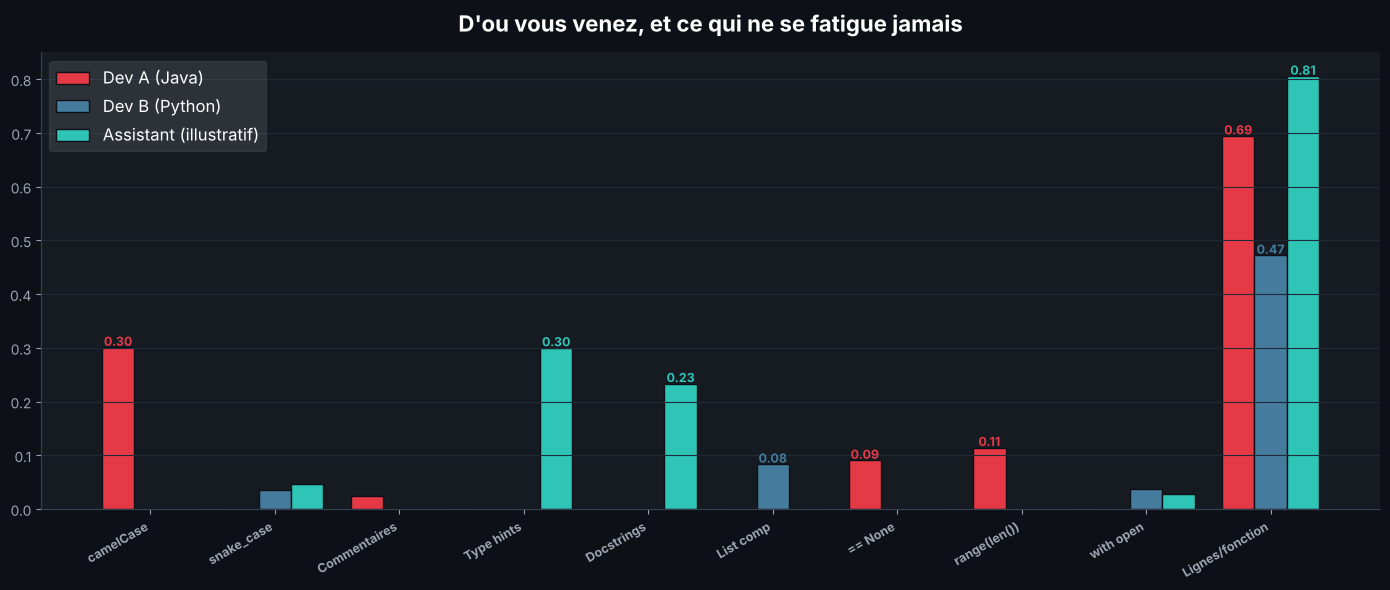

camelCase  : Dev A=0.30  Dev B=0.00  Assistant=0.00
Type hints : Dev A=0.00  Dev B=0.00  Assistant=0.30
Docstrings : Dev A=0.00  Dev B=0.00  Assistant=0.23


In [29]:
# ── DIX NOMBRES PAR PROFIL, ET ON TRACE ─────────────────────────────
# Échelle par feature : aucune feature ne doit dominer par sa magnitude
_ALL = np.array([sig(f) for f in A_all + B_all + C_all])
SCALE = np.where(_ALL.max(axis=0) > 0, _ALL.max(axis=0), 1.0)

SA = np.mean([sig(f) for f in A_all], axis=0)
SB = np.mean([sig(f) for f in B_all], axis=0)
SC = np.mean([sig(f) for f in C_all], axis=0)

fig, ax = plt.subplots(figsize=(14,6))
fig.patch.set_facecolor('#0D1117'); ax.set_facecolor('#161B22')
x = np.arange(len(FEATS)); w = 0.26
for offset, vals, lbl, col in [(-w,SA,'Dev A (Java)','#E63946'),(0,SB,'Dev B (Python)','#457B9D'),(w,SC,'Assistant (illustratif)','#2EC4B6')]:
    bars = ax.bar(x + offset, vals, w, label=lbl, color=col, edgecolor='#0D1117')
    for bar, v in zip(bars, vals):
        if v > 0.06:
            ax.text(bar.get_x()+bar.get_width()/2, v+0.003,
                    f'{v:.2f}', ha='center', fontsize=9, color=col, fontweight='bold')
ax.set_xticks(x); ax.set_xticklabels(FEATS, fontsize=9, color='#C9D1D9', fontweight='bold', rotation=30, ha='right')
ax.set_title("D'ou vous venez, et ce qui ne se fatigue jamais",
             fontsize=16, fontweight='bold', color='white', pad=15)
ax.legend(fontsize=12, labelcolor='white', framealpha=0.1)
for sp in ['top','right']: ax.spines[sp].set_visible(False)
for sp in ['bottom','left']: ax.spines[sp].set_color('#374151')
ax.tick_params(colors='#9CA3AF'); ax.set_ylim(0, 0.85)
ax.grid(axis='y', color='#1F2937', linewidth=0.8)
plt.tight_layout(); plt.show()

print(f'camelCase  : Dev A={SA[0]:.2f}  Dev B={SB[0]:.2f}  Assistant={SC[0]:.2f}')
print(f'Type hints : Dev A={SA[3]:.2f}  Dev B={SB[3]:.2f}  Assistant={SC[3]:.2f}')
print(f'Docstrings : Dev A={SA[4]:.2f}  Dev B={SB[4]:.2f}  Assistant={SC[4]:.2f}')

### Cellule 3/3 — Attribution fichier par fichier

**Principe :** pour chaque fichier —
1. On affiche le code
2. La salle vote : *Dev A ? Dev B ? Assistant ?*
3. On lance le programme — le résultat tombe

---

**Setup** — centroïdes calculés une fois ici :


In [30]:
# ╔══════════════════════════════════════════════════════════════════╗
# ║  SPOILER — CETTE CELLULE CONTIENT LES REPONSES DU VOTE.          ║
# ║  L'EXECUTER, PUIS LA REPLIER (double-clic sur la barre a gauche) ║
# ║  AVANT DE MONTER SUR SCENE.                                      ║
# ╚══════════════════════════════════════════════════════════════════╝
# Les quatre fichiers du vote, avec leur reponse.
_queue = [
    ('''
# Validation des donnees d un formulaire
def validateFormData(formData, requiredFields):
    if formData == None: return False
    errorList = []
    for fieldName in requiredFields:
        if fieldName not in formData: errorList.append(fieldName)
        elif formData[fieldName] == '': errorList.append(fieldName)
    return len(errorList) == 0
''', 'Dev A'),
    ('''
def aggregate_logs(log_lines, level='ERROR'):
    if not log_lines: return {}
    filtered = [l for l in log_lines if level in l]
    counts = {}
    for line in filtered:
        src = line.split()[0] if line.split() else 'unknown'
        counts[src] = counts.get(src, 0) + 1
    return counts
''', 'Dev B'),
    ('''
def validate_email(
        email: str,
        strict: bool = True
) -> bool:
    """Validate email address format.
    Args: email: address to validate.
    Returns: True if valid, False otherwise.
    """
    if not email or not isinstance(email, str): return False
    import re as _r
    return bool(_r.match(r"^[a-zA-Z0-9_.+-]+@[a-zA-Z0-9-]+[.][a-zA-Z0-9-.]+$", email))
''', 'Assistant'),
    ('''
def filter_records(
        records: list,
        min_score: float = 0.0
) -> list:
    """Filter records above minimum score threshold."""
    if not records: return []
    return [r for r in records if r.get('score', 0) >= min_score]
''', None),   # None = cas ambigu
]


In [31]:
# ── CENTROIDES ET MECANIQUE DU VOTE ─────────────────────────────────
def vecteur_code(src):
    # SCALE : chaque feature ramenée à une échelle comparable,
    # sinon 'Builtins' et 'Lignes/fonction' écrasent les features discriminantes
    v = np.array(sig(src)) / SCALE
    n = np.linalg.norm(v)
    return v/n if n>0 else v

cA = np.mean([vecteur_code(f) for f in A_all], axis=0)
cB = np.mean([vecteur_code(f) for f in B_all], axis=0)
cC = np.mean([vecteur_code(f) for f in C_all], axis=0)


def afficher(i):
    '''Affiche le fichier i — sans révéler la réponse.
    Indexe, et non sequentiel : sauter un fichier ne decale plus les suivants.'''
    global _current
    _current = _queue[i]
    src, _ = _current
    print(src)
    print('─' * 50)
    print('  Dev A ?   Dev B ?   Assistant ?')
    print('─' * 50)

def révéler():
    '''Révèle la réponse pour le fichier courant.'''
    src, label = _current
    v     = vecteur_code(src)
    dA    = 1 - np.dot(v, cA)
    dB    = 1 - np.dot(v, cB)
    dC    = 1 - np.dot(v, cC)
    dists = {'Dev A': dA, 'Dev B': dB, 'Assistant': dC}
    pred  = min(dists, key=dists.get)
    ratio = (sorted(dists.values())[1] - dists[pred]) / max(dists[pred], 1e-9)
    conf  = 'HAUTE' if ratio>1.5 else ('MOYENNE' if ratio>0.3 else 'FAIBLE')
    icone = '?' if label is None else ('✓' if pred==label else '✗')
    print(f'  [{icone}]  Prédit : {pred}  ({conf} confiance)')
    # une image plutot que des caracteres pleins : lisible au fond de la salle
    _o = sorted(dists, key=dists.get)[::-1]
    fig, ax = scene(11, 2.9)
    ax.barh(range(len(_o)), [1 - min(dists[n], 1) for n in _o], height=.5,
            color=[ACCENT if n == pred else GRIS for n in _o], zorder=3)
    for y, n in enumerate(_o):
        ax.text(1 - min(dists[n], 1) + .012, y, n,
                color=ENCRE if n == pred else ENCRE2, fontsize=17,
                fontweight='bold' if n == pred else 'normal', va='center')
    ax.set_yticks([]); ax.set_xticks([]); ax.grid(False)
    ax.set_xlim(0, 1.3); ax.set_ylim(-.6, len(_o) - .25)
    ax.set_title(f'Proximite au profil  ·  predit : {pred}  ({conf} confiance)',
                 color='white', fontsize=17, fontweight='bold', pad=14, loc='left')
    plt.tight_layout(); plt.show()
    if label:
        print(f'  Réponse : {label}')

print('✓ Prêt — appelez afficher() puis révéler() pour chaque fichier')

✓ Prêt — appelez afficher() puis révéler() pour chaque fichier


---
### Fichier A — OPTIONNEL (hors du speech de 40 minutes)

**🎙️** *"Lisez ce fichier. Dev A, Dev B, ou l'assistant ?"*

*(Laisser 15 secondes — laisser la salle voter à main levée)*


In [32]:
afficher(0)


# Validation des donnees d un formulaire
def validateFormData(formData, requiredFields):
    if formData == None: return False
    errorList = []
    for fieldName in requiredFields:
        if fieldName not in formData: errorList.append(fieldName)
        elif formData[fieldName] == '': errorList.append(fieldName)
    return len(errorList) == 0

──────────────────────────────────────────────────
  Dev A ?   Dev B ?   Assistant ?
──────────────────────────────────────────────────


⏸️ **La salle a voté — révéler le résultat :**


  [✓]  Prédit : Dev A  (MOYENNE confiance)


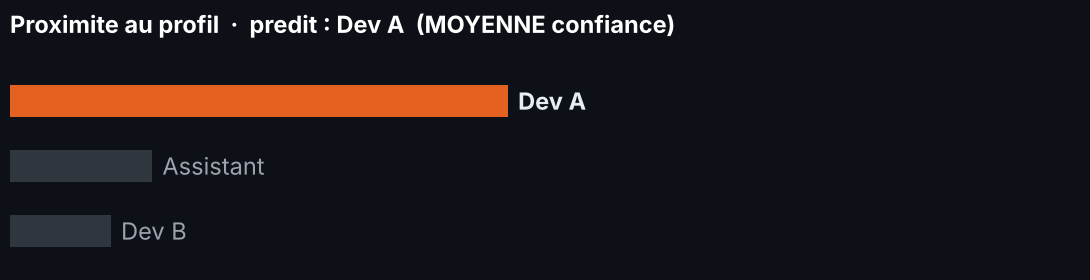

  Réponse : Dev A


In [33]:
révéler()


---
### Fichier B — OPTIONNEL (sauter si tu es en retard)

**🎙️** *"Et celui-là ?"*

*(15 secondes)*


In [34]:
afficher(1)


def aggregate_logs(log_lines, level='ERROR'):
    if not log_lines: return {}
    filtered = [l for l in log_lines if level in l]
    counts = {}
    for line in filtered:
        src = line.split()[0] if line.split() else 'unknown'
        counts[src] = counts.get(src, 0) + 1
    return counts

──────────────────────────────────────────────────
  Dev A ?   Dev B ?   Assistant ?
──────────────────────────────────────────────────


⏸️ **La salle a voté :**


  [✓]  Prédit : Dev B  (FAIBLE confiance)


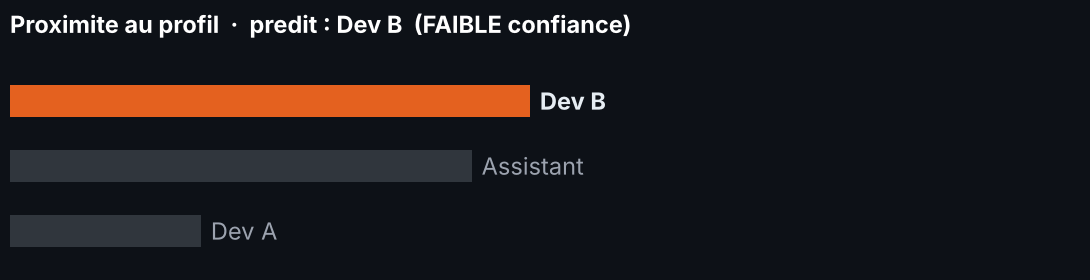

  Réponse : Dev B


In [35]:
révéler()


---
### Fichier C — OPTIONNEL (sauter si tu es en retard)

**🎙️** *"Celui-là ?"*

*(15 secondes)*


In [36]:
afficher(2)


def validate_email(
        email: str,
        strict: bool = True
) -> bool:
    """Validate email address format.
    Args: email: address to validate.
    Returns: True if valid, False otherwise.
    """
    if not email or not isinstance(email, str): return False
    import re as _r
    return bool(_r.match(r"^[a-zA-Z0-9_.+-]+@[a-zA-Z0-9-]+[.][a-zA-Z0-9-.]+$", email))

──────────────────────────────────────────────────
  Dev A ?   Dev B ?   Assistant ?
──────────────────────────────────────────────────


⏸️ **La salle a voté :**


  [✓]  Prédit : Assistant  (HAUTE confiance)


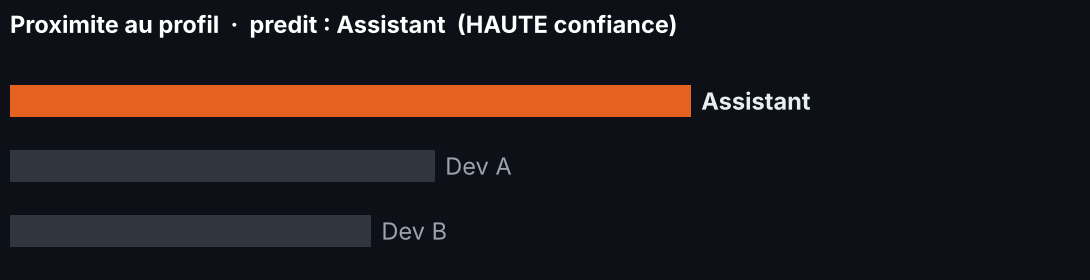

  Réponse : Assistant


In [37]:
révéler()


---
### Fichier D — ⚠️ Le cas difficile  ·  **le seul indispensable**

**🎙️** *"Le dernier. Regardez bien.*
*Celui-là est différent."*

*(20 secondes — laisser la salle hésiter)*

**🎙️ après la révélation :** *"Le modèle voit les deux mains.*
*Il ne nomme que la machine. Et je le dis au plus juste :*
*dans CE fichier, le signal du code assisté masque le co-auteur humain."*


In [38]:
afficher(3)


def filter_records(
        records: list,
        min_score: float = 0.0
) -> list:
    """Filter records above minimum score threshold."""
    if not records: return []
    return [r for r in records if r.get('score', 0) >= min_score]

──────────────────────────────────────────────────
  Dev A ?   Dev B ?   Assistant ?
──────────────────────────────────────────────────


⏸️ **La salle a voté — révéler :**


  [?]  Prédit : Assistant  (MOYENNE confiance)


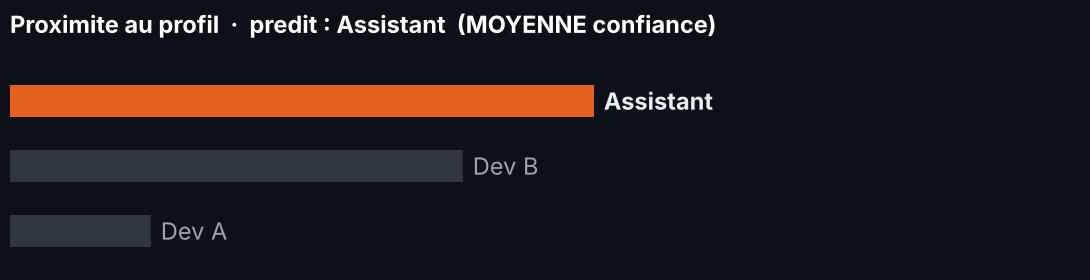


──────────────────────────────────────────────────
  CE FICHIER A ÉTÉ ÉCRIT À DEUX.
──────────────────────────────────────────────────
  Assistant en tête    : type hints, docstring
  Dev B juste derrière : list comprehension, snake_case, fonction courte
  Dev A nulle part

  Le modèle voit les deux mains. Il ne nomme que la machine.

  C est LA limite à retenir : sur du code assisté,
  DANS CE FICHIER, le signal du code assiste masque le co-auteur
  humain. Un fichier ne fait pas une loi.
  "Assistant" ne veut pas dire "pas d humain".


In [39]:
révéler()

print()
print('─' * 50)
print('  CE FICHIER A ÉTÉ ÉCRIT À DEUX.')
print('─' * 50)
print('  Assistant en tête    : type hints, docstring')
print('  Dev B juste derrière : list comprehension, snake_case, fonction courte')
print('  Dev A nulle part')
print()
print('  Le modèle voit les deux mains. Il ne nomme que la machine.')
print()
print('  C est LA limite à retenir : sur du code assisté,')
print('  DANS CE FICHIER, le signal du code assiste masque le co-auteur')
print('  humain. Un fichier ne fait pas une loi.')
print('  "Assistant" ne veut pas dire "pas d humain".')


---

### L'IA a-t-elle une signature ? — la mesure non simulée

**🎙️** *"Tout ce que je vous ai montré sur l'IA jusqu'ici était simulé : les profils,*
*c'est moi qui les ai écrits. Alors j'ai fait le test pour de vrai."*

Corpus : `corpus/ia/assistant.py` — ChatGPT, un seul prompt, 348 lignes non vides.
Pour le refaire avec votre modèle : `corpus/ia/LISEZ-MOI.md`.


In [40]:
# ── TEST IA — la seule mesure d'IA non simulée du talk ────────────────────
#    1/5 — le corpus, et ce qu'il est exactement
import os
CHEMIN_IA = 'corpus/ia/assistant.py'
if not os.path.exists(CHEMIN_IA):
    raise FileNotFoundError(f'{CHEMIN_IA} absent — voir corpus/ia/LISEZ-MOI.md')

IA = [l for l in open(CHEMIN_IA, encoding='utf-8').read().split('\n')
      if l.strip() and not l.startswith('# ')]
# meme regle pour tout le monde : des blocs de 40 lignes NON VIDES.
# sinon les blocs humains (lignes vides comprises) et les blocs IA
# n'ont pas la meme densite, et on mesure la mise en page.
CANDIDATS = {d: [l for l in v if l.strip()] for d, v in CODE.items()}
CANDIDATS['IA'] = IA
print(f'Corpus IA : {len(IA):,} lignes  ·  {len(CANDIDATS)} candidats  ·  hasard 25 %')
print('Genere par un assistant, un seul prompt, aucune consigne de style.')
print()
print('Le corpus est SAIN : le fichier parse, l indentation est intacte.')
print('Le meme code passe par un PDF est dans assistant_via_pdf.py — c est')
print('la meme erreur que le label, version outillage : on mesurerait')
print('le convertisseur, pas la machine. On reste sur des TOKENS.')
print()

Corpus IA : 348 lignes  ·  4 candidats  ·  hasard 25 %
Genere par un assistant, un seul prompt, aucune consigne de style.

Le corpus est SAIN : le fichier parse, l indentation est intacte.
Le meme code passe par un PDF est dans assistant_via_pdf.py — c est
la meme erreur que le label, version outillage : on mesurerait
le convertisseur, pas la machine. On reste sur des TOKENS.



In [41]:
# ── TEST IA  2/5 — la mesure : l'IA contre 3 developpeurs ───────────
_TOKI = lambda s: re.findall(r'[A-Za-z_]+|[^\sA-Za-z_]', s)
_ALLI = '\n'.join('\n'.join(v) for v in CANDIDATS.values())
_VOCI = [w for w, _ in Counter(_TOKI(_ALLI)).most_common(300)]
_PAIRI = [p for p, _ in Counter(zip(_TOKI(_ALLI), _TOKI(_ALLI)[1:])).most_common(300)]

def _fi(s):
    t = _TOKI(s); c = Counter(t); n = max(len(t), 1)
    cp = Counter(zip(t, t[1:])); m = max(len(t)-1, 1)
    noms = re.findall(r'\b([a-zA-Z_][a-zA-Z0-9_]+)\b', s); nn = max(len(noms), 1)
    lg = Counter(min(len(x), 15) for x in noms)
    return np.array([c.get(w, 0)/n for w in _VOCI]
                    + [cp.get(p, 0)/m for p in _PAIRI]
                    + [lg.get(i, 0)/nn for i in range(1, 16)])

TAILLE = 40
B = {q: blocs_code(v, TAILLE) for q, v in CANDIDATS.items()}
k = min(len(b) for b in B.values())
X = {q: np.array([_fi(b) for b in B[q][:k]]) for q in B}
pool = np.vstack(list(X.values())); mu, sd = pool.mean(0), pool.std(0); sd[sd == 0] = 1
Z = {q: (X[q]-mu)/sd for q in X}
rng = np.random.default_rng(5); ntr = max(2, int(k*0.6)); acc = []; conf = Counter(); tot = 0
for _ in range(20):
    idx = {q: rng.permutation(k) for q in Z}
    cen = {q: Z[q][idx[q][:ntr]].mean(0) for q in Z}
    ok = t = 0
    for q in Z:
        for i in idx[q][ntr:]:
            d = {r: np.abs(Z[q][i]-cen[r]).mean() for r in Z}
            pr = min(d, key=d.get); ok += pr == q; t += 1
            if q == 'IA': conf[pr] += 1; tot += 1
    acc.append(ok/t)
a = float(np.mean(acc))
print(f'  blocs de {TAILLE} lignes, {k} par candidat')
print(f'  precision {a*100:.0f} %   hasard 25 %   soit {a*100/25:.1f}x le hasard')
print(f'  les blocs IA sont attribues a : ' + '  '.join(f'{q} {v*100//tot} %' for q, v in conf.most_common()))

  blocs de 40 lignes, 8 par candidat
  precision 69 %   hasard 25 %   soit 2.8x le hasard
  les blocs IA sont attribues a : IA 95 %  Dev 2 5 %


In [42]:
# ╔═══════════════════════════════════════════════════════════════════╗
# ║  HORS DU SPEECH DE 40 MINUTES — a sauter, sauf si tu as de l avance.║
# ║  Le texte qui va avec est dans la version longue du speech.       ║
# ╚═══════════════════════════════════════════════════════════════════╝
# ── TEST IA  3/5 — contre-test : et si je mesurais juste la structure ?
print('CONTRE-TEST : et si le signal n etait que « du code frais,')
print('decoupe en petites fonctions, hors de tout contexte » ?')
print('On refait en retirant def, class, return, import, from, self.')
EX = {'def','class','return','import','from','self'}
_V2 = [w for w, _ in Counter(_TOKI(_ALLI)).most_common(400) if w not in EX][:300]
def _f2(s):
    t = [x for x in _TOKI(s) if x not in EX]; c = Counter(t); n = max(len(t), 1)
    noms = [x for x in re.findall(r'\b([a-zA-Z_][a-zA-Z0-9_]+)\b', s) if x not in EX]
    nn = max(len(noms), 1); lg = Counter(min(len(x), 15) for x in noms)
    return np.array([c.get(w, 0)/n for w in _V2] + [lg.get(i, 0)/nn for i in range(1, 16)])
X2 = {q: np.array([_f2(b) for b in B[q][:k]]) for q in B}
p2 = np.vstack(list(X2.values())); m2, s2 = p2.mean(0), p2.std(0); s2[s2 == 0] = 1
Z2 = {q: (X2[q]-m2)/s2 for q in X2}
rng = np.random.default_rng(5); acc2 = []
for _ in range(20):
    idx = {q: rng.permutation(k) for q in Z2}
    cen = {q: Z2[q][idx[q][:ntr]].mean(0) for q in Z2}
    ok = t = 0
    for q in Z2:
        for i in idx[q][ntr:]:
            d = {r: np.abs(Z2[q][i]-cen[r]).mean() for r in Z2}
            ok += min(d, key=d.get) == q; t += 1
    acc2.append(ok/t)
print(f'  sans ces mots-cles : {np.mean(acc2)*100:.0f} %   soit {np.mean(acc2)*100/25:.1f}x')

CONTRE-TEST : et si le signal n etait que « du code frais,
decoupe en petites fonctions, hors de tout contexte » ?
On refait en retirant def, class, return, import, from, self.


  sans ces mots-cles : 74 %   soit 3.0x


In [43]:
# ── TEST IA  4/5 — contre-test decisif : neuf contre vieux ──────────
# ── LE CONTRE-TEST DÉCISIF : humains NEUFS ───────────────────────
print()
print('DERNIER CONTRE-TEST, et c est le plus important.')
print('Mes humains ecrivent du code de PRODUCTION : vieux, refactore')
print('vingt fois. L IA ecrit du code NEUF, d un coup. Peut-etre que')
print('je mesure « neuf contre vieux », pas « machine contre humain ».')
print()
print('Alors j ai extrait du code humain NEUF : uniquement les lignes')
print('ajoutees lors de la CREATION de fichiers. Jamais refactore.')
print()
# meme regle que pour les devs : on garde les commentaires des auteurs,
# on ne retire que les lignes d en-tete que j ai ajoutees moi-meme.
_ENT = ('# Lignes ajoutees', '# Extraites')
NEUF = {f'Humain neuf {i}':
        [l for l in open(f'corpus/neuf/humain_{i}.py', encoding='utf-8').read().split('\n')
         if l.strip() and not l.startswith(_ENT)] for i in (1, 2, 3)}
C2 = dict(NEUF); C2['IA'] = IA
B2 = {q: blocs_code(v, TAILLE) for q, v in C2.items()}
k2 = min(len(b) for b in B2.values())
_A2 = '\n'.join('\n'.join(v) for v in C2.values())
_V3 = [w for w, _ in Counter(_TOKI(_A2)).most_common(300)]
def _f3(s):
    t = _TOKI(s); c = Counter(t); n = max(len(t), 1)
    noms = re.findall(r'\b([a-zA-Z_][a-zA-Z0-9_]+)\b', s); nn = max(len(noms), 1)
    lg = Counter(min(len(x), 15) for x in noms)
    return np.array([c.get(w, 0)/n for w in _V3] + [lg.get(i, 0)/nn for i in range(1, 16)])
X3 = {q: np.array([_f3(b) for b in B2[q][:k2]]) for q in B2}
p3 = np.vstack(list(X3.values())); m3, s3 = p3.mean(0), p3.std(0); s3[s3 == 0] = 1
Z3 = {q: (X3[q]-m3)/s3 for q in X3}
rng = np.random.default_rng(5); nt3 = max(2, int(k2*0.6)); acc3 = []; cf = Counter(); tt = 0
for _ in range(20):
    idx = {q: rng.permutation(k2) for q in Z3}
    cen = {q: Z3[q][idx[q][:nt3]].mean(0) for q in Z3}
    ok = t = 0
    for q in Z3:
        for i in idx[q][nt3:]:
            d = {r: np.abs(Z3[q][i]-cen[r]).mean() for r in Z3}
            pr = min(d, key=d.get); ok += pr == q; t += 1
            if q == 'IA': cf[pr] += 1; tt += 1
    acc3.append(ok/t)
a3 = float(np.mean(acc3))
print(f'  IA vs humains PRODUCTION : {a*100:>3.0f} %   soit {a*100/25:.1f}x le hasard')
print(f'  IA vs humains NEUFS      : {a3*100:>3.0f} %   soit {a3*100/25:.1f}x le hasard')
print(f'  blocs IA bien identifies : {cf["IA"]*100//tt} %')
print()
print('=' * 62)
if a3 < a - .02:
    print('  Le signal BAISSE face a du code humain neuf — donc une partie')
    print('  venait bien du « neuf contre vieux ». Mais il ne disparait pas.')
else:
    print('  Le signal ne baisse pas face a du code humain neuf : ce n etait')
    print('  pas « neuf contre vieux » que je mesurais.')
print(f'  Il reste a {a3 * 100 / 25:.1f} fois le hasard.')
print('=' * 62)


DERNIER CONTRE-TEST, et c est le plus important.
Mes humains ecrivent du code de PRODUCTION : vieux, refactore
vingt fois. L IA ecrit du code NEUF, d un coup. Peut-etre que
je mesure « neuf contre vieux », pas « machine contre humain ».

Alors j ai extrait du code humain NEUF : uniquement les lignes
ajoutees lors de la CREATION de fichiers. Jamais refactore.



  IA vs humains PRODUCTION :  69 %   soit 2.8x le hasard
  IA vs humains NEUFS      :  72 %   soit 2.9x le hasard
  blocs IA bien identifies : 82 %

  Le signal ne baisse pas face a du code humain neuf : ce n etait
  pas « neuf contre vieux » que je mesurais.
  Il reste a 2.9 fois le hasard.


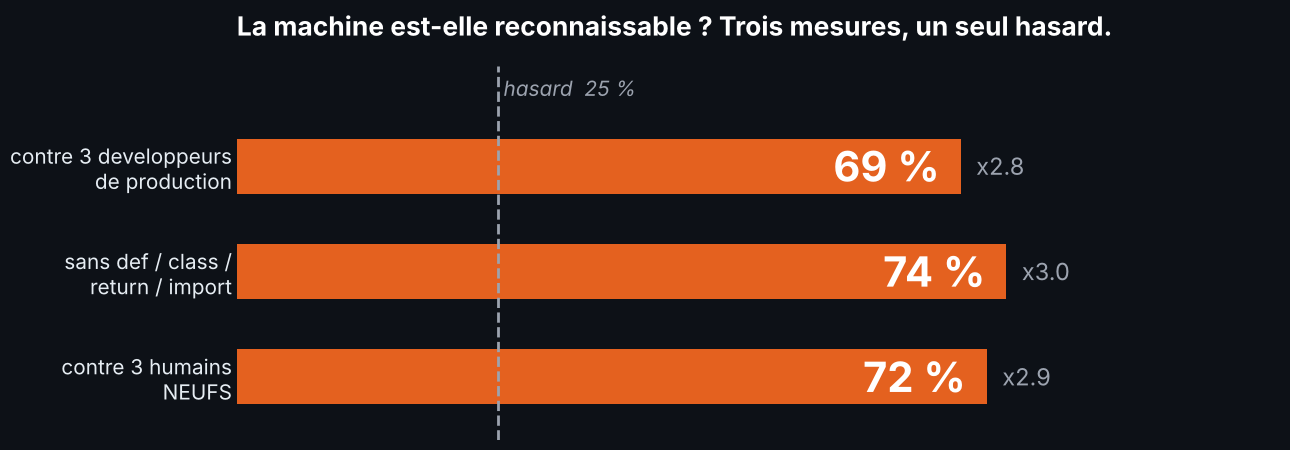

In [44]:
# ── LA MESURE IA, EN UNE IMAGE ──────────────────────────────────────
fig, ax = scene(13, 4.6)
noms  = ['contre 3 developpeurs\nde production', 'sans def / class /\nreturn / import',
         'contre 3 humains\nNEUFS']
vals  = [a*100, float(np.mean(acc2))*100, a3*100]
y     = np.arange(3)[::-1]
ax.barh(y, vals, height=.52, color=ACCENT, zorder=3)
ax.axvline(25, color=ENCRE2, ls='--', lw=2, zorder=4)
ax.text(25, 2.62, ' hasard  25 %', color=ENCRE2, fontsize=15, style='italic', va='bottom')
for yy, v in zip(y, vals):
    ax.text(v - 2, yy, f'{v:.0f} %', color='white', fontsize=30, fontweight='bold',
            va='center', ha='right', zorder=5)
    ax.text(v + 1.5, yy, f'x{v/25:.1f}', color=ENCRE2, fontsize=17, va='center')
ax.set_yticks(y); ax.set_yticklabels(noms, color=ENCRE, fontsize=15)
ax.set_xlim(0, 100); ax.set_xticks([]); ax.set_ylim(-.6, 2.95)
ax.set_title("La machine est-elle reconnaissable ? Trois mesures, un seul hasard.",
             color='white', fontsize=19, fontweight='bold', pad=22, loc='left')
plt.tight_layout(); plt.show()

In [45]:
# ╔═══════════════════════════════════════════════════════════════════╗
# ║  HORS DU SPEECH DE 40 MINUTES — le resultat est sur la slide 14.  ║
# ║  A lancer si on te demande le detail (6 secondes de calcul).      ║
# ╚═══════════════════════════════════════════════════════════════════╝
# ── TEST IA — le contre-test du 84 %, applique a la machine ──────────
# Meme protocole, une seule chose change : les blocs voisins ne sont plus
# jamais des deux cotes (fenetre de test contigue, qu on fait glisser).
# Script complet, courbe et features lisibles comprises : experiments/contre_tests.py
import subprocess, sys as _s
_r = subprocess.run([_s.executable, 'experiments/contre_tests.py', '--ia'], capture_output=True, text=True)
print(_r.stdout if _r.returncode == 0 else 'LE CONTRE-TEST A ECHOUE :\n' + _r.stderr)
print('LECTURE (colonne « glissant », celle de la slide 14) : 52 a 66 % a quatre')
print('candidats ; la machine reconnue dans 80 a 100 % de ses blocs. Le decoupage')
print('contigu unique, plus bruite (un seul essai) : 44 a 69 %, et 75 a 100 %.')
print('Ce sont les humains qu il confond entre eux, pas la machine.')


3. LE TEST IA (8 blocs de 40 lignes par candidat) — hasard 25 %
                                                 publie  contigu  glissant    train  glis.+train
IA contre 3 devs de production                      69%      44%      52%      72%      62%
   dont blocs IA reconnus                           95%      75%      90%      89%     100%
   blocs humains pris pour l IA                      3%       0%      10%       0%       5%
idem, sans def/class/return/import/from/self        74%      69%      62%      71%      62%
   dont blocs IA reconnus                           95%     100%     100%      98%     100%
   blocs humains pris pour l IA                      5%       0%       7%       5%       2%
IA contre 3 humains neufs                           72%      56%      66%      69%      64%
   dont blocs IA reconnus                           82%     100%      80%      84%      95%
   blocs humains pris pour l IA                      9%      25%      10%       8%       8%

  8 blocs 

In [46]:
# ── TEST IA  5/5 — ce que je ne peux PAS dire ───────────────────────
print('=' * 62)
_x = sorted(v * 100 / 25 for v in (a, float(np.mean(acc2)), a3))
print(f'  LE SIGNAL EXISTE. De {_x[0]:.1f} a {_x[-1]:.1f} fois le hasard, et il tient au contre-test.')
print('=' * 62)
print()
print('CE QUE JE PEUX DIRE : ce modele, ce prompt, ce jour-la, ce domaine.')
print(f'Et dit au plus juste : {a * 100:.0f} %, ce n est pas la precision d un detecteur')
print('d IA. C est un resultat experimental sur CE corpus, CE protocole.')
print('CE QUE JE NE PEUX PAS : que « l IA » en general ait une signature.')
print('  · 8 blocs par candidat — echantillon minuscule')
_nh = sum(len(v) for q, v in CANDIDATS.items() if q != 'IA') + sum(len(v) for v in NEUF.values())
print(f'  · {len(IA)} lignes d IA contre {_nh:,} lignes d humains'.replace(',', ' '))
print('  · l IA ecrit un microframework HTTP ; les trois developpeurs, un ORM et')
print('    des utilitaires. Pas le meme sujet — d ou le piege du vocabulaire, juste apres.')
print('  · un seul modele, un seul prompt, une seule conversation')

  LE SIGNAL EXISTE. De 2.8 a 3.0 fois le hasard, et il tient au contre-test.

CE QUE JE PEUX DIRE : ce modele, ce prompt, ce jour-la, ce domaine.
Et dit au plus juste : 69 %, ce n est pas la precision d un detecteur
d IA. C est un resultat experimental sur CE corpus, CE protocole.
CE QUE JE NE PEUX PAS : que « l IA » en general ait une signature.
  · 8 blocs par candidat — echantillon minuscule
  · 348 lignes d IA contre 12 619 lignes d humains
  · l IA ecrit un microframework HTTP ; les trois developpeurs, un ORM et
    des utilitaires. Pas le meme sujet — d ou le piege du vocabulaire, juste apres.
  · un seul modele, un seul prompt, une seule conversation


---

## La signature, en détail

Le test précédent dit **qu'il y a** un signal. Il ne dit pas **en quoi** il consiste.
Deux façons de le demander — une qui tient, une qui ne tient pas.

In [47]:
# ── A QUOI ELLE SE RECONNAIT — 7 mesures, fichier par fichier ───────
# Pas de classifieur ici. Juste sept nombres, lisibles, comparables.
# 6 humains : 3 de production (dev_1..3) + 3 de code neuf (humain_1..3).
# 1 fichier d'IA. On regarde si l'IA sort de la PLAGE humaine, pas de sa moyenne.

def _brut(p):
    """Le fichier entier, moins les lignes d'en-tete que j'ai ajoutees moi-meme."""
    prefixes = ('# Lignes ajoutees', '# Extraites', '# Code genere', '# Domaine :',
                '# Ce fichier', '# Le meme code', '# conserve dans')
    return '\n'.join(l for l in open(p, encoding='utf-8').read().split('\n')
                     if not l.startswith(prefixes))

FICHIERS = {f'Dev {i}': f'corpus/devs/dev_{i}.py' for i in (1, 2, 3)}
FICHIERS.update({f'Neuf {i}': f'corpus/neuf/humain_{i}.py' for i in (1, 2, 3)})
TEXTES = {k: _brut(v) for k, v in FICHIERS.items()}
TEXTES['IA'] = _brut('corpus/ia/assistant.py')

def mesures(t):
    L  = [l for l in t.split('\n') if l.strip()]; n = max(len(L), 1)
    nf = max(len(re.findall(r'\bdef\s', t)), 1)
    nm = re.findall(r'\b([a-zA-Z_][a-zA-Z0-9_]+)\b', t)
    comp = (len(re.findall(r'\[[^\]\n]+\bfor\b[^\]\n]+\bin\b[^\]\n]+\]', t))
            + len(re.findall(r'\{[^}\n]+\bfor\b[^}\n]+\bin\b[^}\n]+\}', t)))
    return {
        'comprehensions /100l': 100*comp/n,
        'ternaires /100l'     : 100*len(re.findall(r'=\s*[^\n=]+\bif\b[^\n]+\belse\b', t))/n,
        'try/except /100l'    : 100*len(re.findall(r'\bexcept\b', t))/n,
        'commentaires %'      : 100*sum(1 for l in L if l.strip().startswith('#'))/n,
        'lignes/fonction'     : n/nf,
        'type hints /100l'    : 100*len(re.findall(r':\s*(?:int|str|float|bool|list|dict|tuple)\b', t))/n,
        'noms 1-2 car. %'     : 100*sum(1 for x in nm if len(x) <= 2)/max(len(nm), 1),
    }

In [48]:
# ── LA MACHINE SORT-ELLE DE LA PLAGE DES SIX HUMAINS ? ─────────────
M = {k: mesures(t) for k, t in TEXTES.items()}
HUM = [k for k in FICHIERS]

print(f"{'mesure':<22}" + ''.join(f'{k:>8}' for k in HUM) + f"{'IA':>8}    plage humaine       verdict")
print('-' * 104)
hors, _nets, _peu, _dedans = 0, [], [], []
for f in M['IA']:
    vals = [M[k][f] for k in HUM]; lo, hi, v = min(vals), max(vals), M['IA'][f]
    marge = v / hi - 1 if v > hi else (1 - v / lo if v < lo else 0)
    if v > hi:   verdict, ecart = 'HORS', f'x{v/hi:.2f} au-dessus'
    elif v < lo: verdict, ecart = 'HORS', ('sous tous les humains'
                                        + (f' (de {100*(1-v/lo):.0f} %)' if v else ''))
    else:        verdict, ecart = 'dans', 'ne separe pas'
    hors += verdict == 'HORS'
    (_dedans if verdict == 'dans' else _peu if marge < .15 else _nets).append((f.split(' /')[0].split(' %')[0], marge))
    print(f'{f:<22}' + ''.join(f'{M[k][f]:>8.2f}' for k in HUM)
          + f'{v:>8.2f}    {lo:>5.2f} - {hi:<6.2f}   {verdict}  {ecart}')
print('-' * 104)
print(f'{hors} mesures sur 7 placent ce fichier hors de la plage des six humains.')
print()
print('  nettement dehors : ' + ', '.join(f for f, _ in _nets))
print('  dehors, de peu   : ' + (', '.join(f'{f} ({m*100:.0f} %)' for f, m in _peu) or 'aucune'))
print('  dedans           : ' + (', '.join(f for f, _ in _dedans) or 'aucune'))
print()
print(f"HONNETEMENT : sur un fichier de {len([l for l in TEXTES['IA'].split(chr(10)) if l.strip()])} lignes, sortir de la plage humaine de")
print("moins de 15 %, c'est du bruit. Je ne retiens que les « nettement ».")
print('Je les montre toutes les sept, y compris celles qui me contredisent.')


mesure                   Dev 1   Dev 2   Dev 3  Neuf 1  Neuf 2  Neuf 3      IA    plage humaine       verdict
--------------------------------------------------------------------------------------------------------
comprehensions /100l      0.60    1.00    0.27    0.10    0.61    0.00    1.72     0.00 - 1.00     HORS  x1.72 au-dessus
ternaires /100l           0.50    0.70    0.30    0.03    0.00    0.00    0.86     0.00 - 0.70     HORS  x1.23 au-dessus
try/except /100l          1.70    1.50    0.53    0.65    0.00    0.00    1.72     0.00 - 1.70     HORS  x1.01 au-dessus
commentaires %            9.13    4.10   10.03    9.78    1.22    4.09    0.00     1.22 - 10.03    HORS  sous tous les humains
lignes/fonction          15.71   22.56   14.71   10.19    5.84    8.95    5.27     5.84 - 22.56    HORS  sous tous les humains (de 10 %)
type hints /100l          0.10    0.47    0.00    0.00    0.00    0.00    0.29     0.00 - 0.47     dans  ne separe pas
noms 1-2 car. %          10.60    8.09 

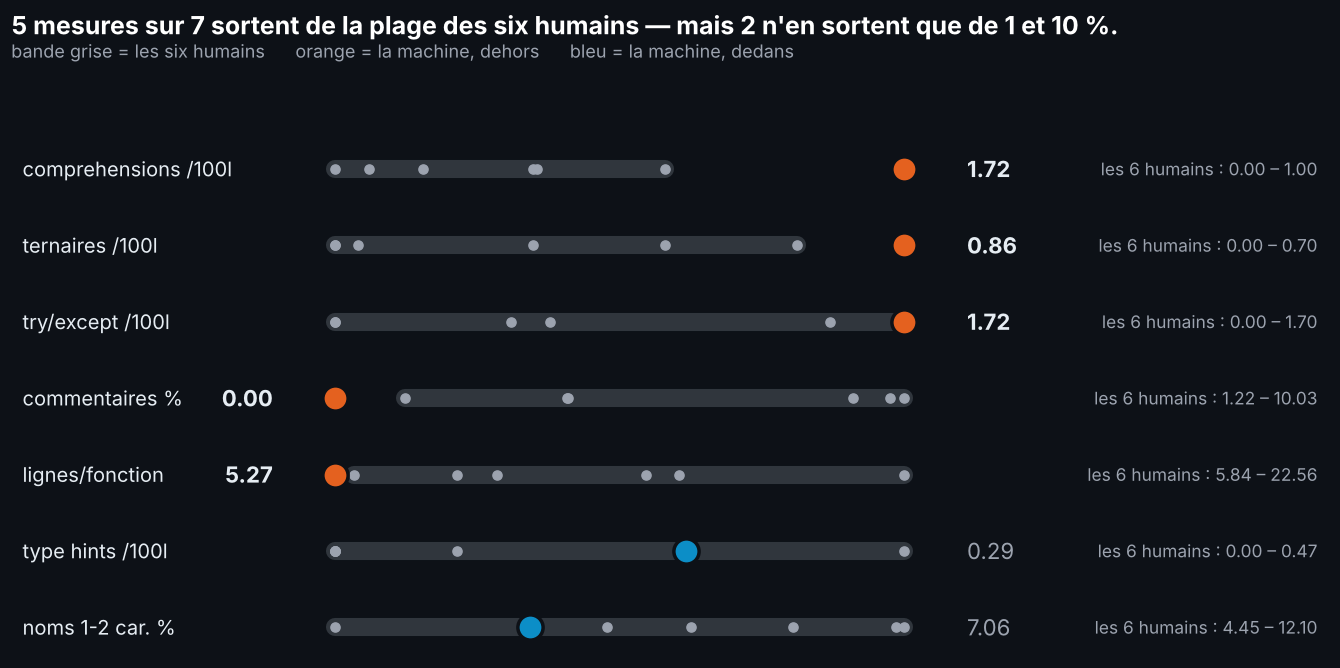

In [49]:
# ── LES 7 MESURES, EN UNE IMAGE ─────────────────────────────────────
# Petits multiples : chaque mesure garde SON unite et SON echelle. Normaliser
# tout sur un axe commun faisait exploser les lignes ou la plage humaine est
# etroite — et trois points sortaient du cadre. Une ligne = une mesure.
lignes = list(M['IA'])
fig, axes = plt.subplots(len(lignes), 1, figsize=(13.5, 6.8))
fig.patch.set_facecolor(FOND)
n_hors = n_limite = 0; _lim = []
for ax, f in zip(axes, lignes):
    vals = [M[k][f] for k in HUM]; lo, hi, v = min(vals), max(vals), M['IA'][f]
    dedans = lo <= v <= hi
    marge  = 0 if dedans else (v/hi - 1 if v > hi else 1 - v/lo)
    n_hors += not dedans
    n_limite += (not dedans) and marge < 0.15
    if (not dedans) and marge < 0.15: _lim.append(f'{marge * 100:.0f}')
    ax.set_facecolor(FOND)
    for s in ax.spines.values(): s.set_visible(False)
    ax.set_yticks([]); ax.set_xticks([])
    bas, haut = min(lo, v), max(hi, v)
    pad = (haut - bas) * .22 or .1
    ax.set_xlim(bas - pad * 2.6, haut + pad * 3.4); ax.set_ylim(-1, 1)
    ax.plot([lo, hi], [0, 0], lw=13, color=GRIS, solid_capstyle='round', zorder=2)
    ax.scatter(vals, [0]*len(vals), s=44, color=ENCRE2, zorder=3)
    ax.scatter([v], [0], s=330, color=BLEU if dedans else ACCENT,
               edgecolors=FOND, linewidths=2.5, zorder=5)
    ax.text(bas - pad * 2.5, 0, f, color=ENCRE, fontsize=14.5, va='center', ha='left')
    # la valeur ne chevauche jamais la bande : dehors a droite du point,
    # dedans a droite de la bande.
    if dedans:
        xt, ha, poids = haut + pad * .5, 'left', 'normal'
    elif v >= hi:
        xt, ha, poids = v + pad * .5, 'left', 'bold'
    else:
        xt, ha, poids = v - pad * .5, 'right', 'bold'
    ax.text(xt, 0, f'{v:,.2f}'.replace(',', ' '),
            color=ENCRE if not dedans else ENCRE2, fontsize=16,
            fontweight=poids, va='center', ha=ha)
    ax.text(haut + pad * 3.3, 0, 'les 6 humains : ' + f'{lo:,.2f} – {hi:,.2f}'.replace(',', ' '),
            color=ENCRE2, fontsize=12.5, va='center', ha='right')
fig.suptitle(f"{n_hors} mesures sur 7 sortent de la plage des six humains"
             + (f" — mais {n_limite} n'en sortent que de {' et '.join(_lim)} %." if n_limite else '.'),
             color='white', fontsize=18, fontweight='bold', x=.012, ha='left', y=.975)
fig.text(.012, .905, 'bande grise = les six humains      orange = la machine, dehors      '
         'bleu = la machine, dedans', color=ENCRE2, fontsize=13, ha='left')
plt.tight_layout(rect=[0, 0, 1, .875]); plt.show()


In [50]:
# ╔═══════════════════════════════════════════════════════════════════╗
# ║  HORS DU SPEECH DE 40 MINUTES — le resultat est sur la slide 15.  ║
# ║  A lancer si on te demande le detail (8 secondes de calcul).      ║
# ╚═══════════════════════════════════════════════════════════════════╝
# ── UN SECOND MODELE — l'objection du fichier unique ────────────────
# Tout le code « IA » ci-dessus vient d'UN fichier, d'UN modele (ChatGPT).
# Second fichier : un autre modele (Claude), meme domaine, un seul prompt,
# aucune consigne de style, ecrit par un agent qui ne connaissait pas
# l'experience. Prompt exact : en tete de corpus/ia/assistant_2.py.
import subprocess, sys as _s
_r = subprocess.run([_s.executable, 'experiments/deux_fichiers_ia.py'], capture_output=True, text=True)
print(_r.stdout if _r.returncode == 0 else 'LE TEST A ECHOUE :\n' + _r.stderr)
print('LECTURE : le second modele est reconnu lui aussi, mais il ne garde qu un')
print('des trois traits du premier — les ternaires. Il commente, et ses')
print('comprehensions restent dans la plage humaine. Ce tableau-la (slide 15),')
print('c est la signature de CE modele, pas de « la machine ».')


Fichier 1 (ChatGPT) : 348 lignes non vides  ·  fichier 2 (Claude) : 733 lignes non vides

A. LE TEST PUBLIE, REJOUE SUR LE SECOND FICHIER — hasard 25 %
                                                 publie  glissant   (blocs IA reconnus)
contre 3 devs de production                         68%       59%   (100 % / 100 %)
idem, sans def/class/return/import/from/self        69%       62%   (100 % / 100 %)
contre 3 humains neufs                              77%       71%   (99 % / 100 %)

B. APPRENDRE SUR UN FICHIER, TESTER SUR L AUTRE
                                                IA reconnus  humains -> IA  4 classes
  apprend sur ChatGPT, teste sur Claude
    contre 3 devs de production                         70%             0%        65%
    idem, sans def/class/return/import/from/self          95%            20%        66%
    contre 3 humains neufs                              92%            45%        64%
  apprend sur Claude, teste sur ChatGPT
    contre 3 devs de production   

In [51]:
# ╔═══════════════════════════════════════════════════════════════════╗
# ║  HORS DU SPEECH DE 40 MINUTES — cette cellule ET la suivante.     ║
# ║  Le texte qui va avec est dans la version longue du speech.       ║
# ╚═══════════════════════════════════════════════════════════════════╝
# ── « ET SI JE REGARDAIS PLUTOT LE VOCABULAIRE ? » ───────────────────
# C'est la question qu'on pose toujours. Voici la reponse, et pourquoi
# il faut la jeter.

def ratios(a, b, seuil=40, n=6):
    """Tokens que a surutilise / sous-utilise par rapport a b."""
    TOKI = lambda s: re.findall(r"[A-Za-z_]+|[^\sA-Za-z_]", s)
    ta, tb = TOKI(a), TOKI(b)
    ca, cb = Counter(ta), Counter(tb)
    na, nb = max(len(ta), 1), max(len(tb), 1)
    # lissage +1 sur les COMPTES : « 48 fois contre 0 » donne x52, pas x1547.
    out = [(w, ((ca[w] + 1) / na) / ((cb[w] + 1) / nb))
           for w in set(ca) | set(cb)
           if ca[w] + cb[w] >= seuil and (w.isalpha() or '_' in w)]
    out.sort(key=lambda x: (-x[1], x[0]))      # ex aequo : ordre alphabetique, pas le hasard
    return out[:n], out[-n:][::-1]

HUMAINS = '\n'.join(TEXTES[k] for k in FICHIERS)

plus, moins = ratios(TEXTES['IA'], HUMAINS)
print("CE QUE L'IA SURUTILISE, face aux six humains")
print('   ' + '   '.join(f'{w} x{r:.0f}' for w, r in plus))
print("CE QU'ELLE N'ECRIT JAMAIS")
print('   ' + '   '.join(w for w, _ in moins))
print()
print("Voila. « La signature de l'IA », c'est " + ', '.join(w for w, _ in plus[:4]) + '.')
print("Autrement dit : le vocabulaire de ce qu'on lui a demande d'ecrire. Et ce qui lui")
print('manque, c est ' + ', '.join(w for w, _ in moins[:4]) + ' — le vocabulaire des depots des humains.')
print()
print('CONTRE-TEST — le meme calcul entre DEUX HUMAINS du meme depot :')
p2, m2 = ratios(TEXTES['Dev 1'], TEXTES['Dev 2'])
print('   Dev 1 surutilise : ' + '   '.join(f'{w} x{r:.0f}' for w, r in p2))
print("   Dev 1 n'ecrit jamais : " + '   '.join(w for w, _ in m2))
print()
print('=' * 70)
print('  PIEGE 1 / 4   —   « le sujet deguise », version IA')
print('  Deux humains du meme depot se separent sur ' + ', '.join(w for w, _ in p2[:3]) + '.')
print("  Ce n'est pas un style. C'est un repertoire.")
print('  Le lexique ne mesure pas la machine : il mesure le fichier sur')
print("  lequel elle a travaille. D'ou la mesure d'avant — purement")
print('  syntaxique, aucun nom de domaine dedans.')
print('=' * 70)


CE QUE L'IA SURUTILISE, face aux six humains
   strip x18   response x13   method x13   split x13   result x12   values x10
CE QU'ELLE N'ECRIT JAMAIS
   the   django   to   a   app   s

Voila. « La signature de l'IA », c'est strip, response, method, split.
Autrement dit : le vocabulaire de ce qu'on lui a demande d'ecrire. Et ce qui lui
manque, c est the, django, to, a — le vocabulaire des depots des humains.

CONTRE-TEST — le meme calcul entre DEUX HUMAINS du meme depot :
   Dev 1 surutilise : models x52   db x37   expression x29   query x11   list x6   that x6
   Dev 1 n'ecrit jamais : gettext   gettext_lazy   log   ngettext   num   count

  PIEGE 1 / 4   —   « le sujet deguise », version IA
  Deux humains du meme depot se separent sur models, db, expression.
  Ce n'est pas un style. C'est un repertoire.
  Le lexique ne mesure pas la machine : il mesure le fichier sur
  lequel elle a travaille. D'ou la mesure d'avant — purement
  syntaxique, aucun nom de domaine dedans.


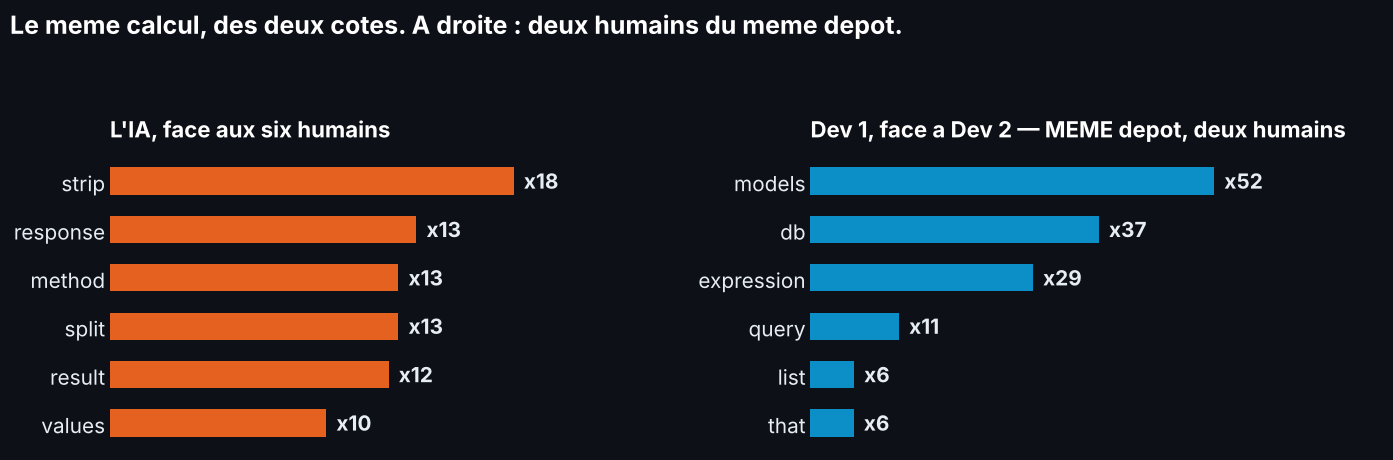

x18 d un cote. x52 de l autre. Ce n est pas un style, c est un repertoire.


In [52]:
# ── LE PIEGE DU VOCABULAIRE, EN UNE IMAGE ───────────────────────────
# Deux facettes, chacune avec SON echelle : les deux ordres de grandeur sur un
# meme axe rendraient la premiere invisible. C'est le rapport entre les deux
# qui est l'argument, pas leur valeur absolue.
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
fig.patch.set_facecolor(FOND)
for ax, (titre, donnees, couleur) in zip(axes, [
        ("L'IA, face aux six humains", plus, ACCENT),
        ("Dev 1, face a Dev 2 — MEME depot, deux humains", p2, BLEU)]):
    ax.set_facecolor(FOND)
    for sp in ax.spines.values(): sp.set_visible(False)
    mots = [w for w, _ in donnees][::-1]; vals = [r for _, r in donnees][::-1]
    ax.barh(range(len(mots)), vals, height=.56, color=couleur, zorder=3)
    for y, (m, v) in enumerate(zip(mots, vals)):
        ax.text(v + max(vals) * .025, y, f'x{v:,.0f}'.replace(',', ' '),
                color=ENCRE, fontsize=15, fontweight='bold', va='center')
    ax.set_yticks(range(len(mots))); ax.set_yticklabels(mots, color=ENCRE, fontsize=15)
    ax.set_xticks([]); ax.set_xlim(0, max(vals) * 1.42); ax.grid(False)
    ax.tick_params(length=0)
    ax.set_title(titre, color='white', fontsize=16, fontweight='bold', pad=12, loc='left')
fig.suptitle("Le meme calcul, des deux cotes. A droite : deux humains du meme depot.",
             color='white', fontsize=18, fontweight='bold', x=.008, ha='left', y=.99)
plt.tight_layout(rect=[0, 0, 1, .89]); plt.show()
print(f'x{plus[0][1]:.0f} d un cote. x{p2[0][1]:.0f} de l autre. Ce n est pas un style, c est un repertoire.')

---

### 🔴 Le même développeur, avant et après juin 2021

**🎙️** *"Dernière question : est-ce que l'IA a déjà changé votre façon de coder ?*
*Le même humain, avant et après juin 2021."*

Corpus : `corpus/eras/` — un contributeur de flask, ses lignes réellement ajoutées,
découpées par période. Commits massifs exclus.


In [53]:
# ── LE MÊME DÉVELOPPEUR, DEUX ÉPOQUES ────────────────────────────────
AVANT = [l for l in open('corpus/eras/avant.py', encoding='utf-8').read().split('\n')
         if l.strip() and not l.startswith('# ')]
APRES = [l for l in open('corpus/eras/apres.py', encoding='utf-8').read().split('\n')
         if l.strip() and not l.startswith('# ')]
print(f'avant juin 2021 : {len(AVANT):,} lignes')
print(f'apres           : {len(APRES):,} lignes\n')

def profil(src):
    lines = src.split('\n'); ne = [l for l in lines if l.strip()]; n = max(len(ne), 1)
    noms = re.findall(r'\b([a-zA-Z_][a-zA-Z0-9_]+)\b', src); nn = max(len(noms), 1)
    return {
      'type hints'  : len(re.findall(r':\s*(int|str|float|bool|list|dict|tuple|Optional|Union|Any)', src))/n,
      'docstrings'  : len(re.findall(r'"""', src))/n,
      'commentaires': sum(1 for l in lines if l.strip().startswith('#'))/n,
      'noms longs'  : len([x for x in noms if len(x) > 10])/nn,
      'list comp'   : len(re.findall(r'\[.+for .+in .+\]', src))/n,
    }

a, b = profil('\n'.join(AVANT)), profil('\n'.join(APRES))
print(f"{'feature':<15}{'avant':>9}{'apres':>9}{'variation':>13}")
print('-' * 47)
for k in a:
    v = (b[k]-a[k])/max(a[k], 1e-9)*100
    print(f'{k:<15}{a[k]:>9.3f}{b[k]:>9.3f}{v:>+12.0f} %' + ('   <<<' if abs(v) > 60 else ''))
print('-' * 47)
print()
print('Le style a bouge. Beaucoup. Et c est le meme humain.')

avant juin 2021 : 6,536 lignes
apres           : 4,357 lignes

feature            avant    apres    variation
-----------------------------------------------
type hints         0.002    0.048       +2118 %   <<<
docstrings         0.002    0.000         -77 %   <<<
commentaires       0.069    0.042         -38 %
noms longs         0.095    0.122         +28 %
list comp          0.002    0.001         -37 %
-----------------------------------------------

Le style a bouge. Beaucoup. Et c est le meme humain.


In [54]:
# ── CE QU'ON PEUT EN TIRER, ET CE QU'ON NE PEUT PAS ─────────────────
_v = (b['type hints'] - a['type hints']) / max(a['type hints'], 1e-9) * 100
print('CE QUE JE RETIENS, ET C EST DEJA BEAUCOUP :')
print('  · le style d un meme developpeur a bouge, fortement et mesurablement')
print(f'  · {_v:+.0f} % de type hints, ce n est PAS forcement Copilot :')
print('    c est aussi Python 3.9, mypy, et les conventions du projet')
print('  · donc un profil de reference vieillit, quelle que soit la cause')
print()
print('LA REGLE : reconstruisez vos profils sur du code recent. Toujours.')
print()
print("=" * 60)
print("  PIEGE 4 / 4   —   \"la cause\"")
print("  un deplacement reel, une cause indemontrable")
print("=" * 60)


CE QUE JE RETIENS, ET C EST DEJA BEAUCOUP :
  · le style d un meme developpeur a bouge, fortement et mesurablement
  · +2118 % de type hints, ce n est PAS forcement Copilot :
    c est aussi Python 3.9, mypy, et les conventions du projet
  · donc un profil de reference vieillit, quelle que soit la cause

LA REGLE : reconstruisez vos profils sur du code recent. Toujours.

  PIEGE 4 / 4   —   "la cause"
  un deplacement reel, une cause indemontrable


---

## 🎤 La conclusion — à dire lentement

---

**🎙️**

> *"Pendant longtemps, le style était une empreinte humaine stable.*

> *Puis on l'a mesurée.*

> *Puis on a appris à la reproduire.*

> *Et maintenant… on ne sait plus si elle appartient à l'auteur ou au modèle."*

*(pause)*

> *"La vraie question n'est plus : qui a écrit ce texte ?*

> ***Mais : qui contrôle encore la signature de ce texte."***

*(silence — 3 secondes — ne pas expliquer)*

---

## Plan B si une cellule plante

| Problème | Réponse |
|----------|---------|
| Kernel qui redémarre | Les outputs sont dans le notebook — lecture seule |
| Cellule lente | Laisser tourner, commenter à l'oral |
| Tout plante | *"Je vous épargne les 3 secondes"* + citer les chiffres |
